<b><font size="6" color="#1779A8">Homework · Previsão de recompra a 90 dias</font></b><br>
<b><font size="4">Everything & Then Some · Parte 1: Importação e Exploração dos Dados (EDA)</font></b><br>

Cada linha de `train.csv` é uma **ocasião de compra** de um cliente; o target
`repeat_purchase_90d` vale 1 se o mesmo cliente voltar a comprar nos 90 dias
seguintes. `clientes.csv` é uma tabela opcional ao nível do cliente, ligada por
`customer_id`.

Este notebook cobre o ponto 1 do enunciado: inspecionar os dados, descrever
observações e variáveis, verificar qualidade e inconsistências, e explorar
relações univariadas e multivariadas. A exploração é feita **duas vezes**:
primeiro sobre `train.csv` tal como chega e depois de juntar `clientes.csv`, para
decidir se essa junção acrescenta informação.

**Nada aqui altera os dados.** As vistas temporárias usadas para medir (por
exemplo, com os valores impossíveis tapados) servem apenas para não deixar um
código administrativo distorcer uma estatística; as decisões de limpeza ficam
registadas no fim e são aplicadas no pré-processamento.

<div class="alert alert-block alert-info">

# Índice<a class="anchor" id="toc"></a>
* [1. Imports e dados](#imports)
* **Parte A · EDA antes do merge (`train.csv`)**
    * [2. Levantamento estrutural](#survey)
    * [3. Variável-alvo](#target)
    * [4. Duplicados, clientes repetidos e tempo](#duplicates)
    * [5. Valores em falta](#missing)
    * [6. Valores impossíveis e regras de domínio](#invalid)
    * [7. Consistência entre colunas](#consistency)
    * [8. Distribuições e outliers](#distributions)
    * [9. Variáveis categóricas](#categorical)
    * [10. Relação com o target](#relevance)
    * [11. Relações multivariadas e redundância](#multivariate)
    * [12. Treino vs teste](#shift)
    * [13. Resumo antes do merge](#summary_a)
* **Parte B · EDA depois do merge (`train.csv` + `clientes.csv`)**
    * [14. Levantamento de `clientes.csv`](#clientes)
    * [15. Merge por `customer_id`](#merge)
    * [16. Qualidade das novas colunas](#merged_quality)
    * [17. Novas colunas e o target](#merged_relevance)
    * [18. Resumo final e decisões para o pré-processamento](#summary_b)

</div>

# <font color='#1779A8'>1. Imports e dados</font> <a class="anchor" id="imports"></a>
[Voltar ao índice](#toc)

Todos os imports do notebook estão nesta célula e nenhuma célula seguinte importa
nada (PEP 8, *"imports are always put at the top of the file"*). À medida que o
homework avançar (pré-processamento, seleção, modelo), os novos imports entram
aqui.

In [1]:
import sys
import warnings
from pathlib import Path

# course_helpers.py (cópia da pasta das práticas) está ao lado deste notebook.
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

# Paleta acessível usada nas práticas: azul para a classe 0, laranja para a 1.
from course_helpers import PLOT_BLUE, PLOT_ORANGE

sns.set_theme(style="whitegrid")
%config InlineBackend.figure_format = 'retina'
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)  # reprodutibilidade
FIGSIZE = (10, 6)
CLASS_PALETTE = {0: PLOT_BLUE, 1: PLOT_ORANGE}

DATA = Path("data")
TARGET = "repeat_purchase_90d"

__Passo 1:__ Ler os quatro ficheiros. `ID` identifica a linha e é a chave da
submissão, por isso vai para o índice em vez de ficar entre as colunas que um
modelo poderia receber por engano. `float_precision="round_trip"` garante que os
valores monetários são lidos exatamente como foram escritos.

In [2]:
read = dict(float_precision="round_trip")
train = pd.read_csv(DATA / "train.csv", index_col="ID", **read)
test = pd.read_csv(DATA / "test.csv", index_col="ID", **read)
clientes = pd.read_csv(DATA / "clientes.csv", **read)
sample_submission = pd.read_csv(DATA / "sample_submission.csv")

pd.DataFrame({
    "linhas": [len(f) for f in (train, test, clientes, sample_submission)],
    "colunas": [f.shape[1] for f in (train, test, clientes, sample_submission)],
}, index=["train", "test", "clientes", "sample_submission"])

,linhas,colunas
train,6534,38
test,986,37
clientes,1143,13
sample_submission,986,2


In [3]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


**6,534 ocasiões de compra no treino e 986 no teste**, com as mesmas 37 features (o teste não tem o target). `clientes.csv` tem 1,143 clientes e 13 colunas, e `sample_submission.csv` tem exatamente uma linha por `ID` do teste, que é o formato a entregar.

# <font color='#1779A8'>Parte A · EDA antes do merge</font>

# <font color='#1779A8'>2. Levantamento estrutural</font> <a class="anchor" id="survey"></a>
[Voltar ao índice](#toc)

Antes de qualquer estatística: para que serve cada coluna, e o que custaria dar o
ficheiro a um modelo tal como está?

__Passo 2:__ Organizar as colunas por **papel**, seguindo os grupos de atributos do
enunciado. O `dtype` diz como o valor está guardado, não o que mede, por isso os
grupos são escritos à mão e verificados contra o ficheiro.

In [4]:
identifiers = ["customer_id"]          # chave de junção, nunca uma feature direta
date_column = "purchase_date"

feature_groups = {
    "monetário (compra atual)": ["Total a Pagar", "Total Bruto", "Total Liquido",
                                 "Total Imp_", "Total Portes", "Total Desc_ Global",
                                 "Total Desc_ Linha", "Custo"],
    "detalhe (compra atual)": ["N_ Detalhes", "invoice_count_current_purchase"],
    "timing histórico": ["days_since_previous_purchase", "customer_tenure_days",
                         "prior_purchase_count", "prior_mean_gap_days",
                         "prior_std_gap_days"],
    "valor histórico": ["prior_total_spend", "prior_mean_purchase_value",
                        "prior_std_purchase_value", "prior_min_purchase_value",
                        "prior_max_purchase_value"],
    "frequência móvel": ["purchase_count_30d", "purchase_count_90d",
                         "purchase_count_180d", "purchase_count_365d"],
    "gasto móvel": ["spend_30d", "spend_90d", "spend_180d", "spend_365d"],
    "ruído": ["random_noise"],
}
numeric = [c for group in feature_groups.values() for c in group]
categorical = [c for c in train.columns
               if c not in numeric + identifiers + [TARGET, date_column]]

# Nenhuma coluna pode ficar sem papel, e o teste tem de ter as mesmas (menos o target).
unassigned = set(train.columns) - set(numeric + categorical + identifiers
                                      + [TARGET, date_column])
print("colunas sem papel:", unassigned or "nenhuma")
print("teste = treino sem o target:", set(train.columns) - set(test.columns) == {TARGET})
print(f"{len(numeric)} numéricas, {len(categorical)} categóricas: {categorical}")

colunas sem papel: nenhuma
teste = treino sem o target: True
29 numéricas, 6 categóricas: ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']


__Passo 3:__ Uma tabela por coluna: tipo, valores distintos, faltas no treino e no
teste, e se uma coluna `float` só contém inteiros (contagens guardadas como
decimais).

In [5]:
survey = pd.DataFrame({
    "papel": {c: g for g, cols in feature_groups.items() for c in cols}
             | {c: "categórica" for c in categorical}
             | {"customer_id": "identificador", date_column: "data", TARGET: "target"},
    "dtype": train.dtypes.astype(str),
    "distintos": train.nunique(),
    "faltas treino": train.isna().sum(),
    "% faltas treino": (100 * train.isna().mean()).round(2),
    "faltas teste": test.isna().sum(),
})
survey["só inteiros"] = [
    pd.api.types.is_float_dtype(train[c]) and bool((train[c].dropna() % 1 == 0).all())
    for c in survey.index
]
survey.loc[train.columns]

,papel,dtype,distintos,faltas treino,% faltas treino,faltas teste,só inteiros
Total a Pagar,monetário (compra atual),float64,6122,65,0.99,0.0,False
Total Bruto,monetário (compra atual),float64,6040,65,0.99,0.0,False
Total Liquido,monetário (compra atual),float64,6095,65,0.99,0.0,False
Total Imp_,monetário (compra atual),float64,5412,65,0.99,0.0,False
Total Portes,monetário (compra atual),float64,215,65,0.99,0.0,False
Total Desc_ Global,monetário (compra atual),float64,109,65,0.99,0.0,False
Total Desc_ Linha,monetário (compra atual),float64,3520,65,0.99,0.0,False
Custo,monetário (compra atual),float64,5758,65,0.99,0.0,False
N_ Detalhes,detalhe (compra atual),float64,171,65,0.99,0.0,True
invoice_count_current_purchase,detalhe (compra atual),float64,5,65,0.99,0.0,True


__Passo 4:__ Listar os níveis das categóricas. O número de níveis diz quão larga a
codificação vai ficar; **quais** são os níveis diz se a coluna significa o que o
nome promete.

In [6]:
levels = train[categorical].nunique().sort_values()
for column in levels.index:
    shares = train[column].value_counts(normalize=True, dropna=False)
    print(f"{column:18s} {levels[column]:3d} níveis | mais frequente:"
          f" {shares.index[0]!s:32s} ({100 * shares.iloc[0]:.1f}%)")

warehouse            2 níveis | mais frequente: Final Excel Warehouse 1          (95.7%)
document_series      3 níveis | mais frequente: Ctrl Z Series 2                  (41.9%)
commercial_zone      5 níveis | mais frequente: Decorative Dashboard Zone 4      (95.8%)
payment_type         9 níveis | mais frequente: Maybe Tomorrow Payment 7         (69.9%)
salesperson          9 níveis | mais frequente: VLOOKUP Master 1                 (62.0%)
transport_method    80 níveis | mais frequente: Maybe Tomorrow Delivery 72       (17.1%)


<div class="alert alert-block alert-success">

**O ficheiro tem 29 numéricas, 6 categóricas, uma data, o identificador `customer_id` e o target.** Três factos estruturais orientam o resto do notebook:

1. **Nove colunas `float` são contagens** (`N_ Detalhes`, `prior_purchase_count`, as quatro `purchase_count_*`, os dias...). Estão guardadas como decimais só porque têm faltas: um `int` do pandas não aceita `NaN`.
2. **`customer_id` é um número e passaria num `select_dtypes("number")`.** Não mede nada do cliente; serve só para juntar `clientes.csv`, e nunca entra como feature tal como está.
3. **As categóricas estão muito concentradas:** `warehouse` e `commercial_zone` têm mais de 95% das linhas num único nível, e `transport_method` tem 80 níveis. Um one-hot ingénuo daria ~108 colunas, a maioria quase vazias.

</div>

# <font color='#1779A8'>3. Variável-alvo</font> <a class="anchor" id="target"></a>
[Voltar ao índice](#toc)

__Passo 5:__ Olhar para o target antes de o cruzar com qualquer outra coisa: a
métrica a reportar depende deste número.

                     linhas  proporção
repeat_purchase_90d                   
0                      2880     0.4408
1                      3654     0.5592

prever sempre a classe maioritária: accuracy 0.5592 e recall 0 na classe 0
baseline do sample_submission (proporções): {1: 0.7515, 0: 0.2485}
IDs do sample_submission = IDs do teste, pela mesma ordem: True


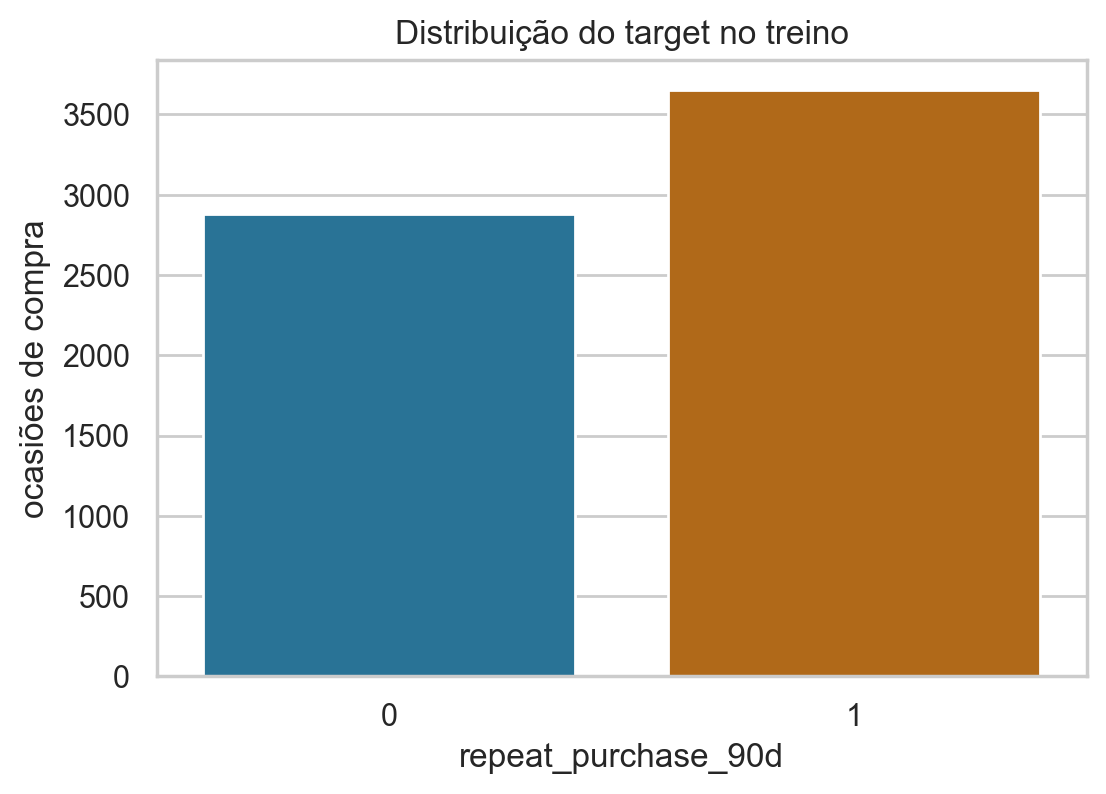

In [7]:
balance = train[TARGET].value_counts().sort_index()
print(balance.to_frame("linhas").assign(
    proporção=lambda f: (f["linhas"] / len(train)).round(4)).to_string())
print(f"\nprever sempre a classe maioritária: accuracy {balance.max() / balance.sum():.4f}"
      f" e recall 0 na classe {balance.idxmin()}")

baseline = sample_submission[TARGET].value_counts(normalize=True).round(4)
print("baseline do sample_submission (proporções):", baseline.to_dict())
print("IDs do sample_submission = IDs do teste, pela mesma ordem:",
      sample_submission["ID"].tolist() == test.index.tolist())

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=balance.index, y=balance.values, hue=balance.index, palette=CLASS_PALETTE,
            legend=False, ax=ax)
ax.set(xlabel="repeat_purchase_90d", ylabel="ocasiões de compra",
       title="Distribuição do target no treino")
plt.show()

**3,654 recompras contra 2,880 não-recompras: 55.92% de classe positiva.** O problema está quase equilibrado, por isso a accuracy é legível, mas um modelo que responde sempre "recompra" já tem 0.5592 de accuracy sem identificar nenhum dos 2,880 casos negativos. Por isso a avaliação vai usar métricas que olham para as duas classes (F1 e, como medida independente do limiar, a AUC-ROC), e 0.5592 é o valor de referência a bater.

O `sample_submission.csv` prevê 1 em 75.15% das linhas do teste. É uma baseline, não uma estimativa da taxa real do teste.

# <font color='#1779A8'>4. Duplicados, clientes repetidos e tempo</font> <a class="anchor" id="duplicates"></a>
[Voltar ao índice](#toc)

Todas as estatísticas seguintes são contagens ou somas sobre linhas, por isso uma
linha repetida conta duas vezes em todas elas. A repetição é medida a três níveis:
linhas exatas, o mesmo cliente na mesma data, e o mesmo cliente em várias linhas.

__Passo 6:__ Contar duplicados. `ID` está no índice, por isso `.duplicated()` já o
ignora.

In [8]:
empty_rows = train[numeric + categorical].isna().all(axis=1)
exact = train.duplicated(keep=False)

print("linhas duplicadas (excesso):", train.duplicated().sum())
print("  das quais são linhas sem nenhuma feature preenchida:",
      (exact & empty_rows).sum(), "de", exact.sum(), "envolvidas")
print("duplicados entre linhas com dados:",
      train[~empty_rows].duplicated().sum())
print("mesmo cliente e mesma data (excesso):",
      train[~empty_rows].duplicated(subset=["customer_id", date_column]).sum())

linhas duplicadas (excesso): 10
  das quais são linhas sem nenhuma feature preenchida: 16 de 16 envolvidas


duplicados entre linhas com dados: 0


mesmo cliente e mesma data (excesso): 0


__Passo 7:__ Quantas ocasiões de compra tem cada cliente, e quantos clientes do
teste já aparecem no treino?

In [9]:
per_customer = train.groupby("customer_id").size()
print(f"{train['customer_id'].nunique()} clientes no treino,"
      f" {test['customer_id'].nunique()} no teste")
print("linhas por cliente no treino:")
print(per_customer.describe().round(1).to_frame("linhas").T.to_string())

top10_share = per_customer.sort_values(ascending=False).head(10).sum() / len(train)
print(f"os 10 clientes com mais linhas concentram {100 * top10_share:.1f}% do treino")

shared = set(test["customer_id"]) & set(train["customer_id"])
in_shared = test["customer_id"].isin(shared)
print(f"clientes do teste que já estão no treino: {len(shared)} de"
      f" {test['customer_id'].nunique()} ({in_shared.sum()} de {len(test)} linhas do teste)")

610 clientes no treino, 206 no teste
linhas por cliente no treino:
        count  mean   std  min  25%  50%   75%    max
linhas  610.0  10.7  20.0  1.0  1.0  4.0  12.0  277.0
os 10 clientes com mais linhas concentram 17.5% do treino
clientes do teste que já estão no treino: 184 de 206 (932 de 986 linhas do teste)


__Passo 8:__ Comparar o período coberto pelo treino e pelo teste.

treino: 2015-07-11 -> 2025-02-15
teste:  2025-05-24 -> 2026-10-06
intervalo entre a última data do treino e a primeira do teste: 98 dias


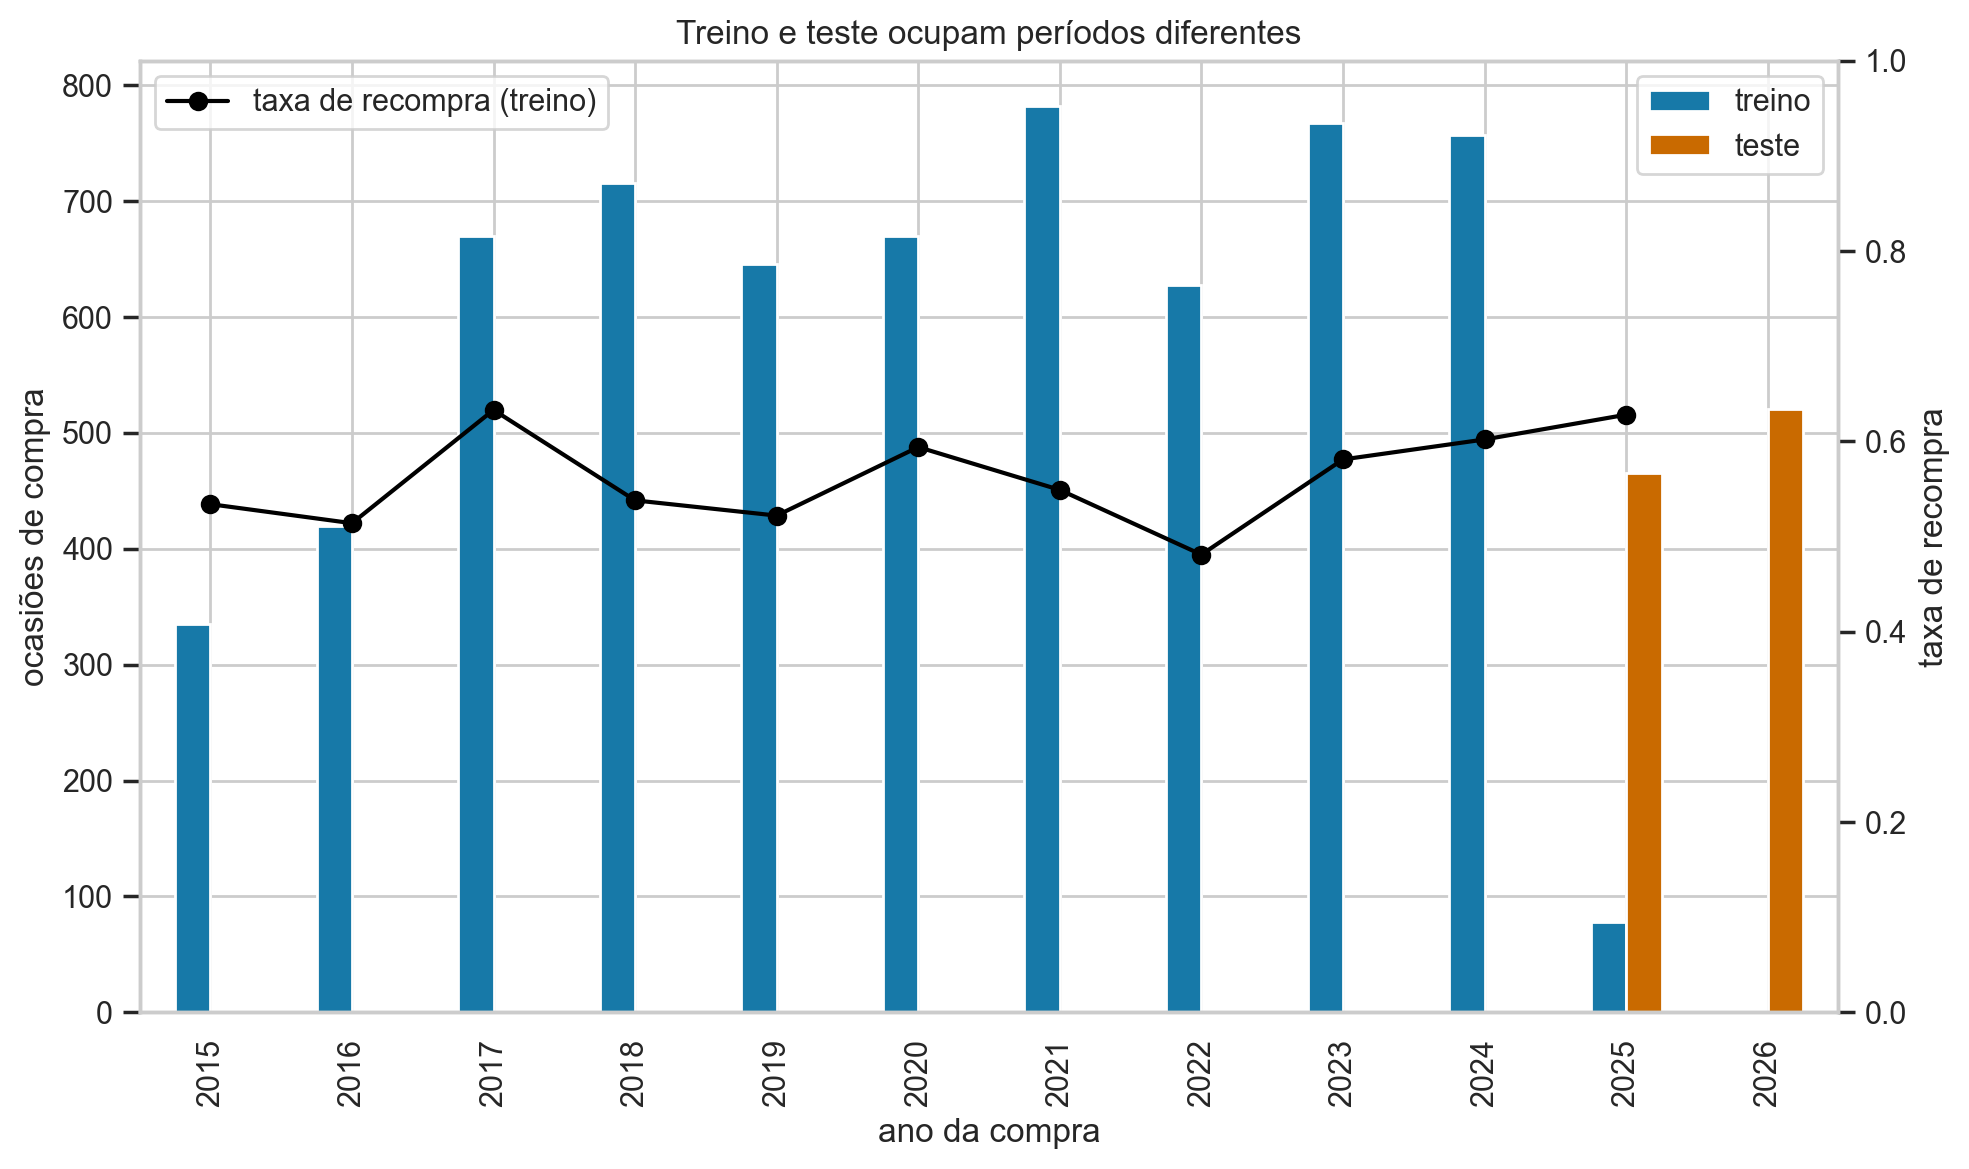

purchase_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
treino,335.000,420.000,670.000,716.000,646.000,670.000,782.000,628.000,767.000,757.000,78.000,NaN
teste,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,465.000,521.0
taxa de recompra (treino),0.534,0.514,0.633,0.538,0.522,0.594,0.549,0.481,0.581,0.602,0.628,NaN


In [10]:
train_dates = pd.to_datetime(train[date_column])
test_dates = pd.to_datetime(test[date_column])
print(f"treino: {train_dates.min().date()} -> {train_dates.max().date()}")
print(f"teste:  {test_dates.min().date()} -> {test_dates.max().date()}")
print(f"intervalo entre a última data do treino e a primeira do teste:"
      f" {(test_dates.min() - train_dates.max()).days} dias")

by_year = pd.DataFrame({
    "treino": train_dates.dt.year.value_counts(),
    "teste": test_dates.dt.year.value_counts(),
    "taxa de recompra (treino)": train.groupby(train_dates.dt.year)[TARGET].mean().round(3),
}).sort_index()
by_year.index = by_year.index.astype(int)

fig, ax = plt.subplots(figsize=FIGSIZE)
by_year[["treino", "teste"]].plot.bar(color=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
ax.set(xlabel="ano da compra", ylabel="ocasiões de compra",
       title="Treino e teste ocupam períodos diferentes")
ax2 = ax.twinx()
ax2.plot(range(len(by_year)), by_year["taxa de recompra (treino)"], color="black",
         marker="o", label="taxa de recompra (treino)")
ax2.set(ylabel="taxa de recompra", ylim=(0, 1))
ax2.grid(False)
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()
by_year.T

<div class="alert alert-block alert-warning">

**Os 10 duplicados exatos são todos linhas vazias** (só `customer_id` e target preenchidos, ver secção 5). Entre as linhas com dados não há nenhum duplicado, nem duas compras do mesmo cliente na mesma data.

**A repetição está um nível acima: 610 clientes para 6,534 linhas.** A mediana é de 4 compras por cliente, o máximo 277, e os 10 clientes mais ativos concentram 17.5% do treino. Os atributos de cliente vão repetir-se nas várias compras de cada cliente, por isso a amostra efetiva de qualquer variável ao nível do cliente é 610, não 6,534.

**O teste é um período posterior:** o treino vai de 2015-07-11 a 2025-02-15, o teste de 2025-05-24 a 2026-10-06, com 98 dias de intervalo entre os dois. 184 dos 206 clientes do teste (932 das 986 linhas) já aparecem no treino. Consequência para a avaliação: uma validação que baralhe as linhas mistura compras futuras e passadas do mesmo cliente e dá uma estimativa otimista. Uma validação que respeite a ordem temporal (treinar no passado, validar no período mais recente) imita melhor a tarefa do Kaggle.

A taxa de recompra anual oscila entre 0.48 (2022) e 0.63 (2017 e 2025), sem tendência clara.

</div>

# <font color='#1779A8'>5. Valores em falta</font> <a class="anchor" id="missing"></a>
[Voltar ao índice](#toc)

Onde estão as faltas, e segundo que eixo? Uma falta pode ser um buraco no ficheiro
ou uma consequência lógica do que a coluna mede (uma média de intervalos não
existe para quem nunca comprou antes).

__Passo 9:__ A visão geral, e as linhas em que nenhuma feature está preenchida.

In [11]:
rows_with_null = train.isna().any(axis=1)
print(f"linhas com pelo menos uma falta: {rows_with_null.sum():,} de {len(train):,}"
      f" ({100 * rows_with_null.mean():.2f}%)")
print(f"colunas com faltas: {(train.isna().sum() > 0).sum()} de {train.shape[1]}")
print(f"células em falta: {train.isna().sum().sum():,}")

print(f"\nlinhas sem nenhuma feature: {empty_rows.sum()} no treino,"
      f" {test[numeric + categorical].isna().all(axis=1).sum()} no teste")
print("colunas preenchidas nessas linhas:",
      train.loc[empty_rows].columns[train.loc[empty_rows].notna().all()].tolist())
print(f"taxa de recompra nessas linhas: {train.loc[empty_rows, TARGET].mean():.3f}"
      f" (vs {train[TARGET].mean():.3f} no total)")

linhas com pelo menos uma falta: 2,605 de 6,534 (39.87%)
colunas com faltas: 36 de 38
células em falta: 9,818

linhas sem nenhuma feature: 65 no treino, 0 no teste
colunas preenchidas nessas linhas: ['repeat_purchase_90d', 'customer_id']
taxa de recompra nessas linhas: 0.508 (vs 0.559 no total)


__Passo 10:__ Retiradas as linhas vazias, as faltas que sobram. A tabela compara
treino e teste e acrescenta a **regra estrutural** esperada para cada coluna
histórica.

In [12]:
filled = train[~empty_rows]
missing = pd.DataFrame({
    "faltas treino": filled.isna().sum(),
    "% treino": (100 * filled.isna().mean()).round(2),
    "faltas teste": test.isna().sum(),
    "% teste": (100 * test.isna().mean()).round(2),
})
missing = missing[missing[["faltas treino", "faltas teste"]].sum(axis=1) > 0]
missing.sort_values("faltas treino", ascending=False)

,faltas treino,% treino,faltas teste,% teste
prior_std_gap_days,1413,21.84,69.0,7.00
prior_mean_gap_days,1243,19.21,76.0,7.71
prior_std_purchase_value,1048,16.20,46.0,4.67
prior_mean_purchase_value,797,12.32,52.0,5.27
days_since_previous_purchase,796,12.30,52.0,5.27
prior_max_purchase_value,603,9.32,22.0,2.23
prior_min_purchase_value,603,9.32,22.0,2.23
transport_method,196,3.03,30.0,3.04
payment_type,195,3.01,30.0,3.04
spend_365d,195,3.01,30.0,3.04


__Passo 11:__ Testar a hipótese estrutural: as faltas das colunas históricas
dependem do número de compras anteriores? Uma média de intervalos precisa de pelo
menos dois intervalos; um desvio-padrão de valores precisa de pelo menos duas
compras.

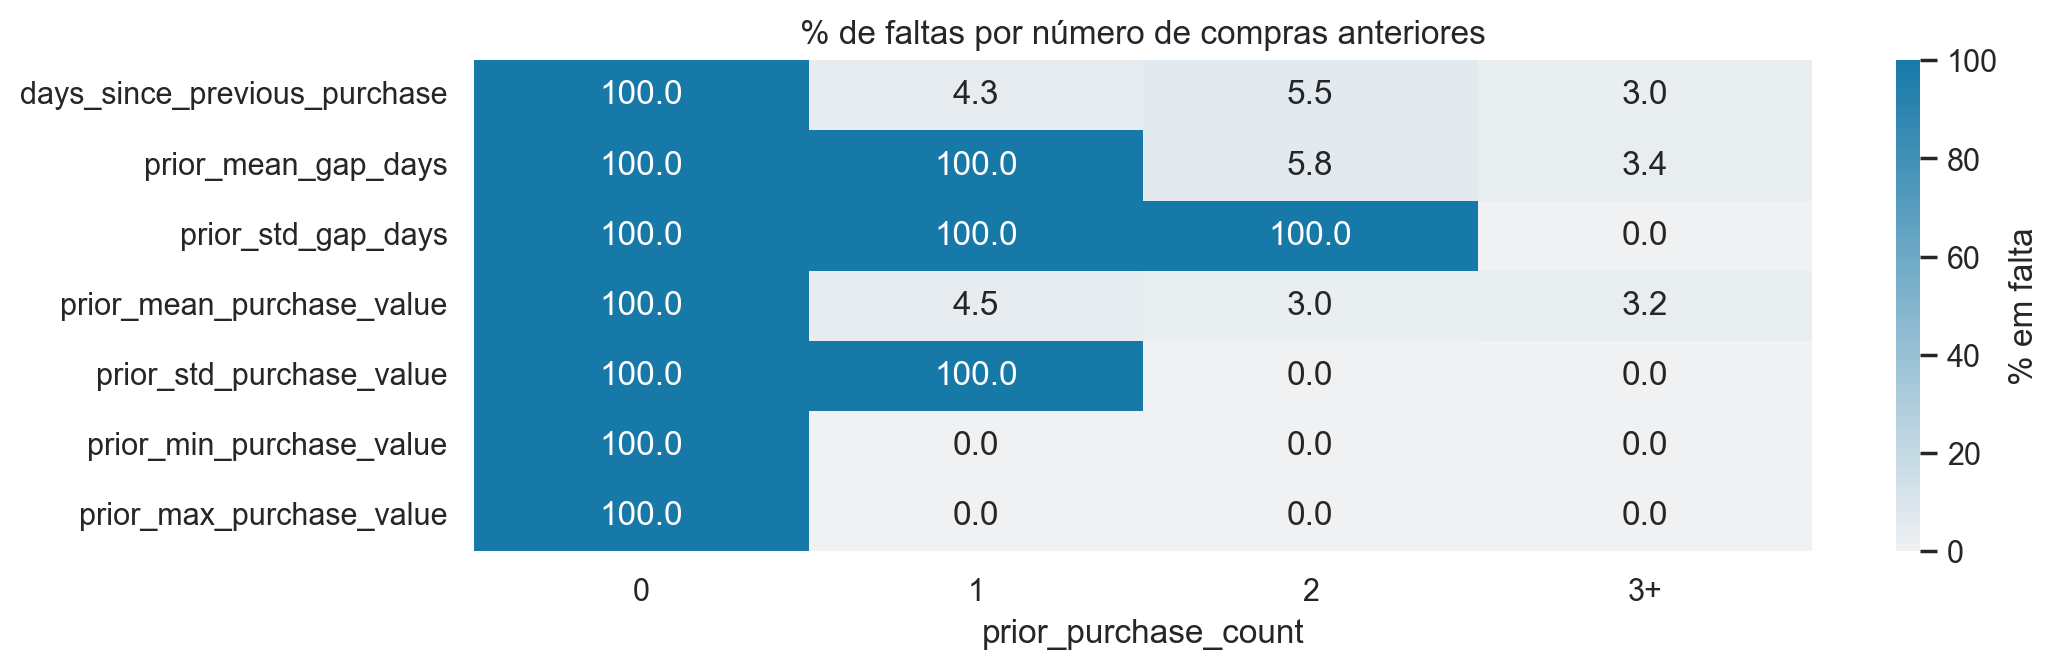

prior_purchase_count,0,1,2,3+
linhas,603,445,365,5056


In [13]:
history = ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days",
           "prior_mean_purchase_value", "prior_std_purchase_value",
           "prior_min_purchase_value", "prior_max_purchase_value"]
count_band = pd.cut(filled["prior_purchase_count"], [-1, 0, 1, 2, np.inf],
                    labels=["0", "1", "2", "3+"])

missing_by_history = (filled[history].isna().groupby(count_band, observed=True).mean() * 100)
missing_by_history.insert(0, "linhas", count_band.value_counts().sort_index())

fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(missing_by_history[history].T, annot=True, fmt=".1f", vmin=0, vmax=100,
            cmap=sns.light_palette(PLOT_BLUE, as_cmap=True),
            cbar_kws={"label": "% em falta"}, ax=ax)
ax.set(xlabel="prior_purchase_count", ylabel="",
       title="% de faltas por número de compras anteriores")
plt.tight_layout()
plt.show()
missing_by_history["linhas"].to_frame().T

__Passo 12:__ As faltas nas categóricas e em `spend_365d` não têm explicação
estrutural. Aparecem em conjunto? E estão ligadas a alguma categórica observada?
Seguindo a semana 3, cada flag de falta é cruzada com as categóricas por
qui-quadrado e **V de Cramér**; o target fica de fora, para que não seja o label a
decidir a limpeza.

In [14]:
block = ["payment_type", "salesperson", "transport_method", "warehouse", "spend_365d"]
block_missing = filled[block].isna()
print("faltas por coluna:", block_missing.sum().to_dict())
print("linhas com faltas em quantas destas 5 colunas:",
      block_missing.sum(axis=1).value_counts().sort_index().to_dict())
co_missing = block_missing.astype(int).T @ block_missing.astype(int)
co_missing

faltas por coluna: {'payment_type': 195, 'salesperson': 194, 'transport_method': 196, 'warehouse': 195, 'spend_365d': 195}
linhas com faltas em quantas destas 5 colunas: {0: 5544, 1: 875, 2: 50}


,payment_type,salesperson,transport_method,warehouse,spend_365d
payment_type,195,4,2,7,5
salesperson,4,194,5,7,4
transport_method,2,5,196,6,4
warehouse,7,7,6,195,6
spend_365d,5,4,4,6,195


In [15]:
def cramers_v(column, outcome):
    """Qui-quadrado numa tabela de contingência, reescalado para [0, 1] (semana 4).

    Devolve a estatística, o p-value, o V de Cramér e a menor contagem esperada.
    O p-value só é legível com todas as contagens esperadas acima de ~5.
    """
    table = pd.crosstab(column, outcome)
    if min(table.shape) < 2:
        return 0.0, float("nan"), 0.0, float(table.to_numpy().min())
    statistic, p, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return statistic, p, v, expected.min()


flags = {"any_block_missing": block_missing.any(axis=1)}
rows = []
for flag_name, flag in flags.items():
    for column in ["commercial_zone", "document_series"]:
        chi2, p, v, min_expected = cramers_v(filled[column].astype(str), flag)
        rows.append({"flag": flag_name, "categórica": column, "chi2": chi2, "p": p,
                     "V de Cramér": v, "menor esperado": min_expected})
    for column in ["prior_purchase_count", "customer_tenure_days", "Total a Pagar"]:
        rows.append({"flag": flag_name, "categórica": column + " (mediana com/sem falta)",
                     "chi2": np.nan, "p": np.nan, "V de Cramér": np.nan,
                     "menor esperado": np.nan,
                     "com falta": filled.loc[flag, column].median(),
                     "sem falta": filled.loc[~flag, column].median()})
pd.DataFrame(rows).round(4)

,flag,categórica,chi2,p,V de Cramér,menor esperado,com falta,sem falta
0,any_block_missing,commercial_zone,7.8828,0.096,0.0349,0.1430,NaN,NaN
1,any_block_missing,document_series,2.9741,0.226,0.0214,261.3851,NaN,NaN
2,any_block_missing,prior_purchase_count (mediana com/sem falta),NaN,NaN,NaN,NaN,11.00,11.000
3,any_block_missing,customer_tenure_days (mediana com/sem falta),NaN,NaN,NaN,NaN,847.00,930.500
4,any_block_missing,Total a Pagar (mediana com/sem falta),NaN,NaN,NaN,NaN,418.11,486.415


<div class="alert alert-block alert-warning">

**As faltas têm três origens diferentes, e cada uma pede um tratamento diferente.**

1. **65 linhas sem nenhuma feature** (só `customer_id` e target). O teste não tem nenhuma linha assim, e a taxa de recompra delas (0.508) não difere muito da global. São candidatas naturais a remoção do treino: não há nada para imputar a partir delas.
2. **Faltas estruturais nas colunas históricas.** O heatmap mostra-o: com `prior_purchase_count = 0` (603 linhas), todas as estatísticas históricas faltam a 100%, porque não há compra anterior; com 1 compra, faltam os desvios-padrão e os intervalos médios, que precisam de pelo menos duas. Estas faltas **não são desconhecidas, são "não se aplica"**, e uma imputação pela mediana inventaria um histórico que não existe. Um indicador "primeira compra" e um preenchimento com significado (por exemplo, 0 dispersão) são alternativas a comparar. Por cima desta estrutura há ainda 3-6% de faltas sem explicação em `days_since_previous_purchase`, `prior_mean_gap_days` e `prior_mean_purchase_value` em clientes que **têm** histórico; essas são faltas comuns, a imputar.
3. **Cerca de 195 faltas aleatórias em cada uma de `payment_type`, `salesperson`, `transport_method`, `warehouse` e `spend_365d`** (~3% cada). Não aparecem em bloco (nenhuma linha tem mais de 2 destas 5 em falta) e a flag de falta não está associada às categóricas observadas (V de Cramér 0.035 e 0.021, p > 0.05), nem a uma mudança visível no histórico do cliente. São compatíveis com faltas completamente aleatórias: uma imputação simples (moda nas categóricas, mediana em `spend_365d`, ajustada só no treino) é defensável.

No teste, as faltas históricas são proporcionalmente menores (2-8% contra 9-22%), coerente com clientes do teste com mais histórico (secção 12).

</div>

# <font color='#1779A8'>6. Valores impossíveis e regras de domínio</font> <a class="anchor" id="invalid"></a>
[Voltar ao índice](#toc)

<div class="alert alert-block alert-info">

**A regra, escrita antes da medição.** Cada coluna tem um conjunto de valores que
pode tomar, fixado pelo que mede: dias, contagens, valores gastos e médias de
valores pertencem a $[0, \infty)$. Um valor fora do domínio não é um valor pequeno,
**não é um valor**. `random_noise` é a única coluna numérica sem domínio de negócio
(é uma normal centrada em zero), por isso os seus negativos são legítimos.

</div>

__Passo 13:__ Encontrar os negativos nas colunas cujo domínio os proíbe.

In [16]:
non_negative = [c for c in numeric if c != "random_noise"]
negatives = (train[non_negative] < 0).sum()
negatives = negatives[negatives > 0]
for column in negatives.index:
    values = train.loc[train[column] < 0, column]
    print(f"{column:30s} {len(values):3d} negativos | valores distintos: {values.nunique():3d}"
          f" | mais frequente: {values.mode().iloc[0]:.2f}")
print("\nteste:", (test[non_negative] < 0).sum()[lambda s: s > 0].to_dict())

days_since_previous_purchase    16 negativos | valores distintos:   1 | mais frequente: -4.00
prior_mean_gap_days             16 negativos | valores distintos:   1 | mais frequente: -4.00
prior_mean_purchase_value       16 negativos | valores distintos:  16 | mais frequente: -2478.66
spend_365d                      15 negativos | valores distintos:  15 | mais frequente: -159115.18

teste: {'days_since_previous_purchase': 2, 'prior_mean_gap_days': 2, 'prior_mean_purchase_value': 2, 'spend_365d': 2}


__Passo 14:__ Valores dispersos indicam dano aleatório; valores que se acumulam num
único número indicam um **código**. Os `-4` de dias são exatamente o mesmo nas duas
colunas. E os negativos das médias de valor: são o valor certo com o sinal trocado?
`prior_mean_purchase_value` deveria ser `prior_total_spend / prior_purchase_count`.

In [17]:
gap_code = (train["days_since_previous_purchase"] < 0) | (train["prior_mean_gap_days"] < 0)
both = (train["days_since_previous_purchase"] < 0) & (train["prior_mean_gap_days"] < 0)
print(f"linhas com -4 em pelo menos uma das duas colunas: {gap_code.sum()}"
      f" | com -4 nas duas: {both.sum()}")
print("prior_purchase_count nessas linhas:",
      train.loc[gap_code, "prior_purchase_count"].describe()[["min", "50%", "max"]].to_dict())

implied_mean = train["prior_total_spend"] / train["prior_purchase_count"].replace(0, np.nan)
negative_mean = train["prior_mean_purchase_value"] < 0
check = pd.DataFrame({
    "prior_mean_purchase_value": train.loc[negative_mean, "prior_mean_purchase_value"],
    "total / count": implied_mean[negative_mean],
})
print("\nnegativos de prior_mean_purchase_value iguais a -(total / count):",
      int(np.isclose(-check.iloc[:, 0], check.iloc[:, 1]).sum()), "de", len(check))
check.head()

linhas com -4 em pelo menos uma das duas colunas: 32 | com -4 nas duas: 0
prior_purchase_count nessas linhas: {'min': 1.0, '50%': 12.5, 'max': 136.0}

negativos de prior_mean_purchase_value iguais a -(total / count): 16 de 16


,prior_mean_purchase_value,total / count
ID,,
10000018,-110.147097,110.147097
10000519,-409.791667,409.791667
10000536,-218.266392,218.266392
10001157,-417.917143,417.917143
10001375,-779.030000,779.030000


In [18]:
negative_spend = train["spend_365d"] < 0
spend_check = train.loc[negative_spend, ["spend_180d", "spend_365d"]].assign(
    abs_365d=lambda f: f["spend_365d"].abs(),
    abs_respeita_180d=lambda f: f["spend_365d"].abs() >= f["spend_180d"] - 0.01)
print(f"spend_365d negativo: {negative_spend.sum()} linhas;"
      f" |spend_365d| >= spend_180d em {spend_check['abs_respeita_180d'].sum()}")
spend_check.head()

spend_365d negativo: 15 linhas; |spend_365d| >= spend_180d em 15


,spend_180d,spend_365d,abs_365d,abs_respeita_180d
ID,,,,
10000300,577.67,-3456.32,3456.32,True
10002022,264.00,-1230.72,1230.72,True
10002033,0.00,-167.18,167.18,True
10002134,0.00,-753.51,753.51,True
10002452,2234.61,-2648.44,2648.44,True


__Passo 15:__ O outro tipo de valor impossível: um número que nenhuma compra deste
negócio atinge. O máximo de `prior_mean_purchase_value` e de `spend_365d` é
exatamente $10^9$.

In [19]:
placeholder = 1e9
for frame_name, frame in [("treino", train), ("teste", test)]:
    hits = (frame[numeric] == placeholder).sum()
    print(frame_name, hits[hits > 0].to_dict())

big = train["prior_mean_purchase_value"] == placeholder
print("\nnas linhas do placeholder, total / count dá:",
      implied_mean[big].round(2).head().tolist())
print("maior valor legítimo de prior_mean_purchase_value:",
      train.loc[~big, "prior_mean_purchase_value"].max().round(2),
      "| de spend_365d:", train.loc[train["spend_365d"] != placeholder, "spend_365d"].max().round(2))

treino {'prior_mean_purchase_value': 16, 'spend_365d': 15}
teste {'prior_mean_purchase_value': 2, 'spend_365d': 2}

nas linhas do placeholder, total / count dá: [1373.88, 541.46, 1147.1, 634.26, 915.12]
maior valor legítimo de prior_mean_purchase_value: 72937.16 | de spend_365d: 522933.21


__Passo 16:__ A partir daqui, as estatísticas são calculadas numa **vista
temporária**, `view`, em que os valores impossíveis passam a `NaN`. Não é a limpeza
final (essa fica para o pré-processamento); é só para que um código administrativo
de $10^9$ não decida uma média, um desvio-padrão ou uma correlação.

In [20]:
invalid_rules = {
    "days_since_previous_purchase": lambda s: s < 0,
    "prior_mean_gap_days": lambda s: s < 0,
    "prior_mean_purchase_value": lambda s: (s < 0) | (s == placeholder),
    "spend_365d": lambda s: (s < 0) | (s == placeholder),
}
view = train[~empty_rows].copy()
for column, rule in invalid_rules.items():
    view[column] = view[column].mask(rule(view[column]))

pd.DataFrame({
    "valores impossíveis (treino)": {c: int(r(train[c]).sum()) for c, r in invalid_rules.items()},
    "valores impossíveis (teste)": {c: int(r(test[c]).sum()) for c, r in invalid_rules.items()},
})

,valores impossíveis (treino),valores impossíveis (teste)
days_since_previous_purchase,16,2
prior_mean_gap_days,16,2
prior_mean_purchase_value,32,4
spend_365d,30,4


<div class="alert alert-block alert-warning">

**Os valores impossíveis são códigos, não ruído aleatório, e quatro colunas os têm.**

- **`-4` em `days_since_previous_purchase` (16 linhas) e em `prior_mean_gap_days` (16 outras linhas).** Um único valor repetido é um código de preenchimento, não uma medição. Nenhum dia pode ser negativo, por isso estas células passam a falta.
- **`prior_mean_purchase_value` negativo (16 linhas): o valor certo com o sinal trocado.** Nas 16, o valor é exatamente $-(\text{prior\_total\_spend} / \text{prior\_purchase\_count})$. Aqui não é preciso imputar: o valor verdadeiro pode ser **reconstruído** pela identidade.
- **`spend_365d` negativo (15 linhas):** valores todos diferentes, e em todas $|\text{spend\_365d}| \geq$ `spend_180d`, o que é consistente com um sinal trocado.
- **O placeholder $10^9$** em `prior_mean_purchase_value` (16) e `spend_365d` (15), mais 2 + 2 no teste. O maior valor legítimo de cada coluna é 72,937 e 522,933. Um único $10^9$ basta para pôr a média de `spend_365d` em 2.4 milhões; é por isso que a `describe()` original parecia absurda.

**O teste tem os mesmos códigos** (2 de cada), por isso a regra de correção tem de ser uma função aplicada da mesma forma aos dois ficheiros, e não uma limpeza feita só no treino.

</div>

# <font color='#1779A8'>7. Consistência entre colunas</font> <a class="anchor" id="consistency"></a>
[Voltar ao índice](#toc)

Muitas colunas são derivadas umas das outras. Cada identidade contabilística ou
lógica é uma verificação gratuita da qualidade do ficheiro, e diz também quais as
colunas que são **redundantes por construção**.

__Passo 17:__ Testar cada identidade e contar as linhas que a violam (tolerância de
1 cêntimo para arredondamentos).

In [21]:
tol = 0.01
v = view
rules = {
    "Total Bruto = Liquido + Desc_ Linha + Desc_ Global":
        (v["Total Bruto"] - v["Total Liquido"] - v["Total Desc_ Linha"]
         - v["Total Desc_ Global"]).abs() > tol,
    "Total a Pagar = Liquido + Imp_":
        (v["Total a Pagar"] - v["Total Liquido"] - v["Total Imp_"]).abs() > tol,
    "Total a Pagar = Liquido + Imp_ + Portes":
        (v["Total a Pagar"] - v["Total Liquido"] - v["Total Imp_"]
         - v["Total Portes"]).abs() > tol,
    "Custo > Total Liquido (venda abaixo do custo)": v["Custo"] > v["Total Liquido"],
    "Custo = 0": v["Custo"] == 0,
    "count_30d <= 90d <= 180d <= 365d":
        (v["purchase_count_30d"] > v["purchase_count_90d"])
        | (v["purchase_count_90d"] > v["purchase_count_180d"])
        | (v["purchase_count_180d"] > v["purchase_count_365d"]),
    "spend_30d <= 90d <= 180d <= 365d":
        (v["spend_30d"] > v["spend_90d"] + tol) | (v["spend_90d"] > v["spend_180d"] + tol)
        | (v["spend_180d"] > v["spend_365d"] + tol),
    "purchase_count_365d <= prior_purchase_count":
        v["purchase_count_365d"] > v["prior_purchase_count"],
    "prior_min <= prior_mean <= prior_max":
        (v["prior_mean_purchase_value"] < v["prior_min_purchase_value"] - tol)
        | (v["prior_mean_purchase_value"] > v["prior_max_purchase_value"] + tol),
    "prior_mean = prior_total_spend / prior_purchase_count":
        (v["prior_mean_purchase_value"] - v["prior_total_spend"]
         / v["prior_purchase_count"].replace(0, np.nan)).abs() > tol,
    "days_since_previous_purchase <= customer_tenure_days":
        v["days_since_previous_purchase"] > v["customer_tenure_days"],
    "prior_purchase_count = 0 -> prior_total_spend = 0":
        (v["prior_purchase_count"] == 0) & (v["prior_total_spend"] != 0),
}
consistency = pd.Series({name: int(mask.sum()) for name, mask in rules.items()},
                        name="linhas que violam")
consistency.to_frame()

,linhas que violam
Total Bruto = Liquido + Desc_ Linha + Desc_ Global,0
Total a Pagar = Liquido + Imp_,0
Total a Pagar = Liquido + Imp_ + Portes,1053
Custo > Total Liquido (venda abaixo do custo),39
Custo = 0,486
count_30d <= 90d <= 180d <= 365d,0
spend_30d <= 90d <= 180d <= 365d,0
purchase_count_365d <= prior_purchase_count,0
prior_min <= prior_mean <= prior_max,45
prior_mean = prior_total_spend / prior_purchase_count,46


__Passo 18:__ Já sem os códigos (negativos e $10^9$), há ainda médias que não batem
certo com `prior_total_spend / prior_purchase_count` e que caem fora de
`[prior_min, prior_max]`. Em quanto se afastam?

In [22]:
implied_view = view["prior_total_spend"] / view["prior_purchase_count"].replace(0, np.nan)
off = rules["prior_mean = prior_total_spend / prior_purchase_count"]
inflation = (view.loc[off, "prior_mean_purchase_value"] / implied_view[off])
print(f"{off.sum()} médias diferentes de total / count; razão média / (total / count):")
print(inflation.describe().round(2).to_frame("razão").T.to_string())
print("dessas, fora de [min, max]:",
      int((off & rules["prior_min <= prior_mean <= prior_max"]).sum()))

46 médias diferentes de total / count; razão média / (total / count):
       count   mean   std   min    25%    50%    75%    max
razão   46.0  16.14  5.51  8.48  11.01  16.07  21.42  24.81
dessas, fora de [min, max]: 45


<div class="alert alert-block alert-success">

**As identidades contabilísticas confirmam-se, e dizem que várias colunas são redundantes por construção.**

- `Total Bruto = Total Liquido + Desc_ Linha + Desc_ Global` e `Total a Pagar = Total Liquido + Imp_` **sem uma única violação**. Os portes já estão dentro do líquido (somá-los outra vez falha em 1,053 linhas, exatamente as que têm portes). Destas cinco colunas, duas são combinações exatas das outras.
- Contagens e gastos móveis são **sempre monótonos** (30d ≤ 90d ≤ 180d ≤ 365d), depois de tapados os códigos. `purchase_count_365d` nunca excede `prior_purchase_count`, e quem não tem compras anteriores tem sempre `prior_total_spend = 0`.
- **`Custo = 0` em 486 linhas** e **custo acima do valor líquido em 39.** São plausíveis (ofertas, amostras, vendas com prejuízo), não impossíveis: ficam como estão.
- **46 médias de valor estão inflacionadas entre 8.5× e 24.8×** em relação a `prior_total_spend / prior_purchase_count`, e 45 delas caem fora de `[prior_min, prior_max]`. Não são códigos (os valores são todos diferentes), mas são impossíveis: a média não pode exceder o máximo. Tal como os sinais trocados, podem ser **reconstruídas** pela identidade, que fica como regra a aplicar a toda a coluna.

</div>

# <font color='#1779A8'>8. Distribuições e outliers</font> <a class="anchor" id="distributions"></a>
[Voltar ao índice](#toc)

__Passo 19:__ `describe()` mais as duas estatísticas que não reporta e que decidem
como ler estas colunas: a **assimetria** e a **% de zeros**. A coluna `50%` é a
mediana, por isso a razão média/mediana sai da própria tabela.

In [23]:
shape = view[numeric].describe().T
shape["média/mediana"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = view[numeric].skew()
shape["% zeros"] = 100 * (view[numeric] == 0).mean()
shape = shape.sort_values("skew", ascending=False)
shape[["mean", "50%", "max", "média/mediana", "skew", "% zeros"]].round(2)

,mean,50%,max,média/mediana,skew,% zeros
Total Desc_ Global,0.35,0.00,218.49,NaN,27.46,98.30
prior_max_purchase_value,2946.38,1783.24,267526.19,1.65,21.34,0.00
prior_mean_purchase_value,957.93,724.90,72937.16,1.32,21.20,0.00
Total Portes,1.15,0.00,181.06,NaN,19.55,83.72
spend_365d,5777.74,2426.60,522933.21,2.38,18.55,12.52
prior_mean_gap_days,96.18,68.61,3199.00,1.40,9.31,0.00
prior_std_gap_days,74.14,50.64,2212.54,1.46,7.77,0.02
days_since_previous_purchase,101.83,57.00,3199.00,1.79,6.53,0.00
invoice_count_current_purchase,1.07,1.00,5.00,1.07,6.44,0.00
Total Desc_ Linha,112.47,13.13,4103.44,8.57,5.92,37.73


__Passo 20:__ As distribuições das famílias monetárias e de contagem, em escala
`log1p` porque a escala original esconde tudo atrás da cauda. A linha laranja é a
mediana, a tracejada a média.

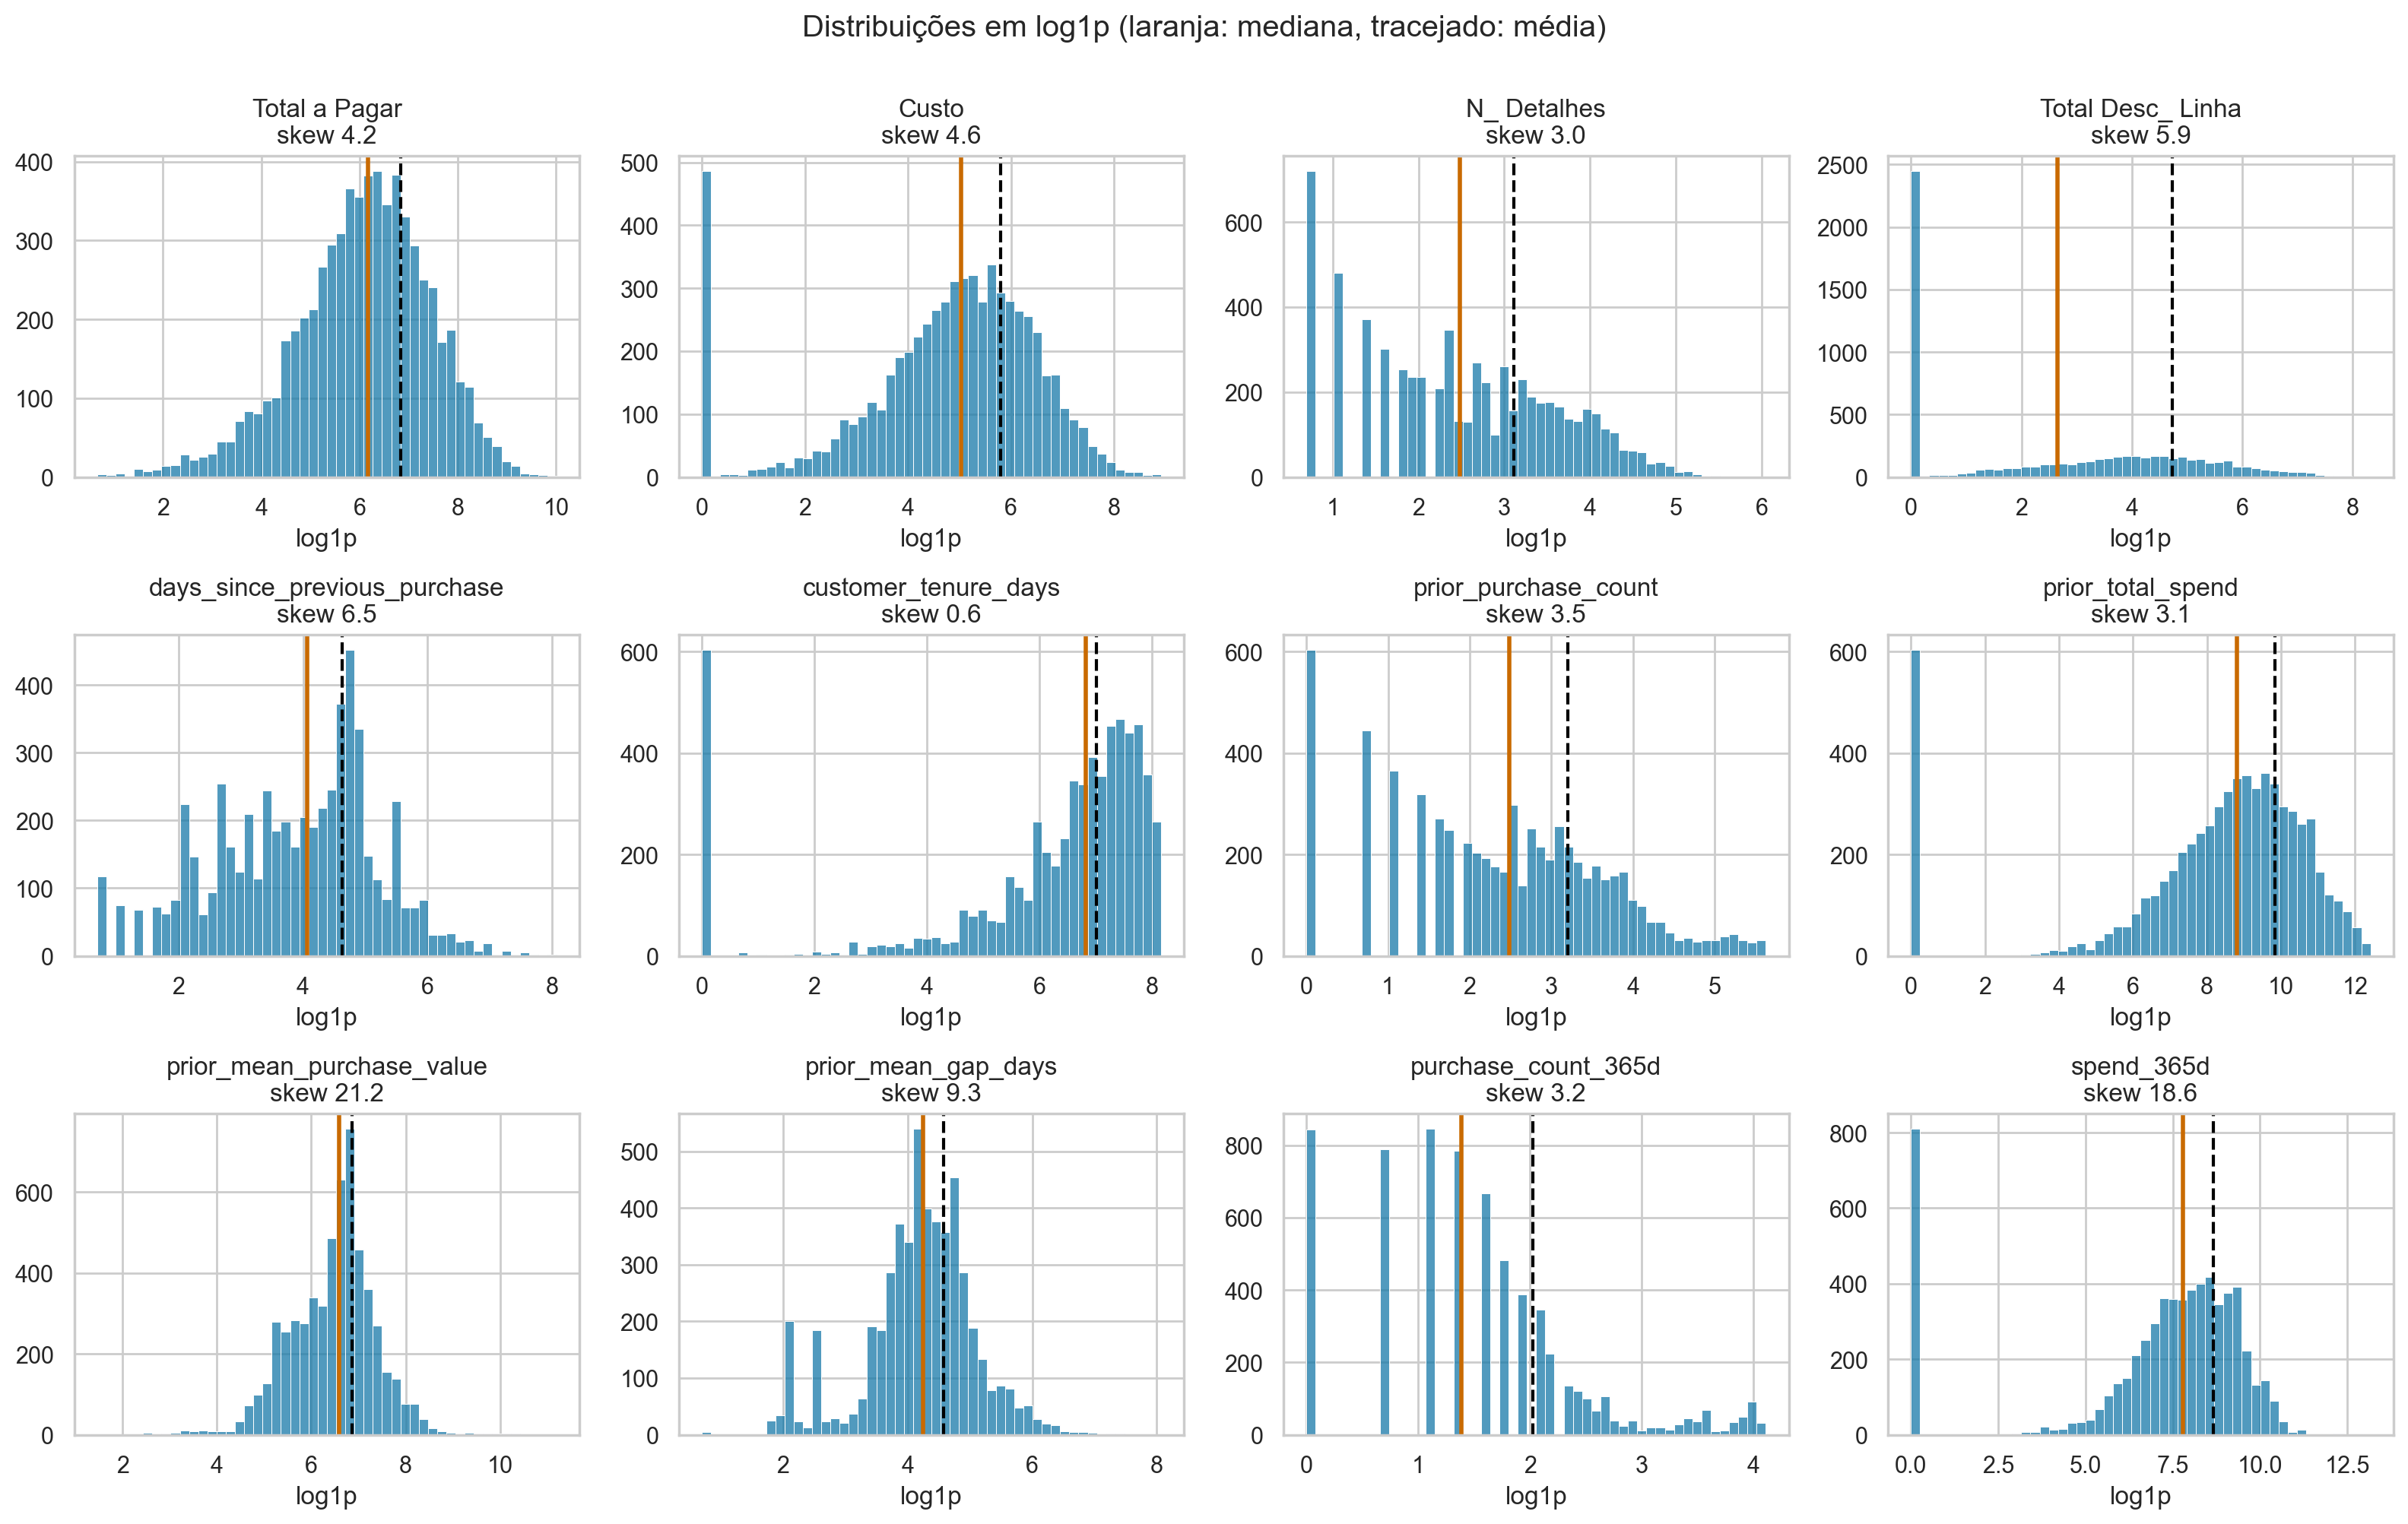

In [24]:
to_plot = ["Total a Pagar", "Custo", "N_ Detalhes", "Total Desc_ Linha",
           "days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count",
           "prior_total_spend", "prior_mean_purchase_value", "prior_mean_gap_days",
           "purchase_count_365d", "spend_365d"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for column, ax in zip(to_plot, axes.ravel()):
    values = np.log1p(view[column].dropna())
    sns.histplot(values, bins=50, color=PLOT_BLUE, ax=ax)
    ax.axvline(np.log1p(view[column].median()), color=PLOT_ORANGE, lw=2)
    ax.axvline(np.log1p(view[column].mean()), color="black", lw=1.5, ls="--")
    ax.set(title=f"{column}\nskew {view[column].skew():.1f}", xlabel="log1p", ylabel="")
plt.suptitle("Distribuições em log1p (laranja: mediana, tracejado: média)", y=1.0)
plt.tight_layout()
plt.show()

__Passo 21:__ A regra do boxplot (1.5 × IQR) só faz sentido numa coluna com
"meio". Contar quantas linhas assinala em cada coluna, ao lado da % de zeros e do
IQR, mostra onde a regra funciona e onde se inverte.

In [25]:
def iqr_flags(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (~series.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum(), iqr


iqr_table = pd.DataFrame(
    {c: dict(zip(["assinaladas", "IQR"], iqr_flags(view[c].dropna()))) for c in numeric}).T
iqr_table["% assinaladas"] = 100 * iqr_table["assinaladas"] / view[numeric].notna().sum()
iqr_table["% zeros"] = shape["% zeros"]
iqr_table.sort_values("% assinaladas", ascending=False).round(2)

,assinaladas,IQR,% assinaladas,% zeros
spend_30d,1060.0,338.24,16.39,67.12
Total Portes,1053.0,0.00,16.28,83.72
Total Desc_ Linha,822.0,92.28,12.71,37.73
prior_min_purchase_value,671.0,147.16,11.44,0.00
purchase_count_180d,737.0,2.00,11.39,21.80
spend_90d,661.0,1514.56,10.22,44.66
prior_total_spend,642.0,20136.77,9.92,9.32
Total a Pagar,592.0,898.75,9.15,0.00
prior_std_gap_days,461.0,45.89,9.12,0.02
Total Liquido,587.0,748.99,9.07,0.00


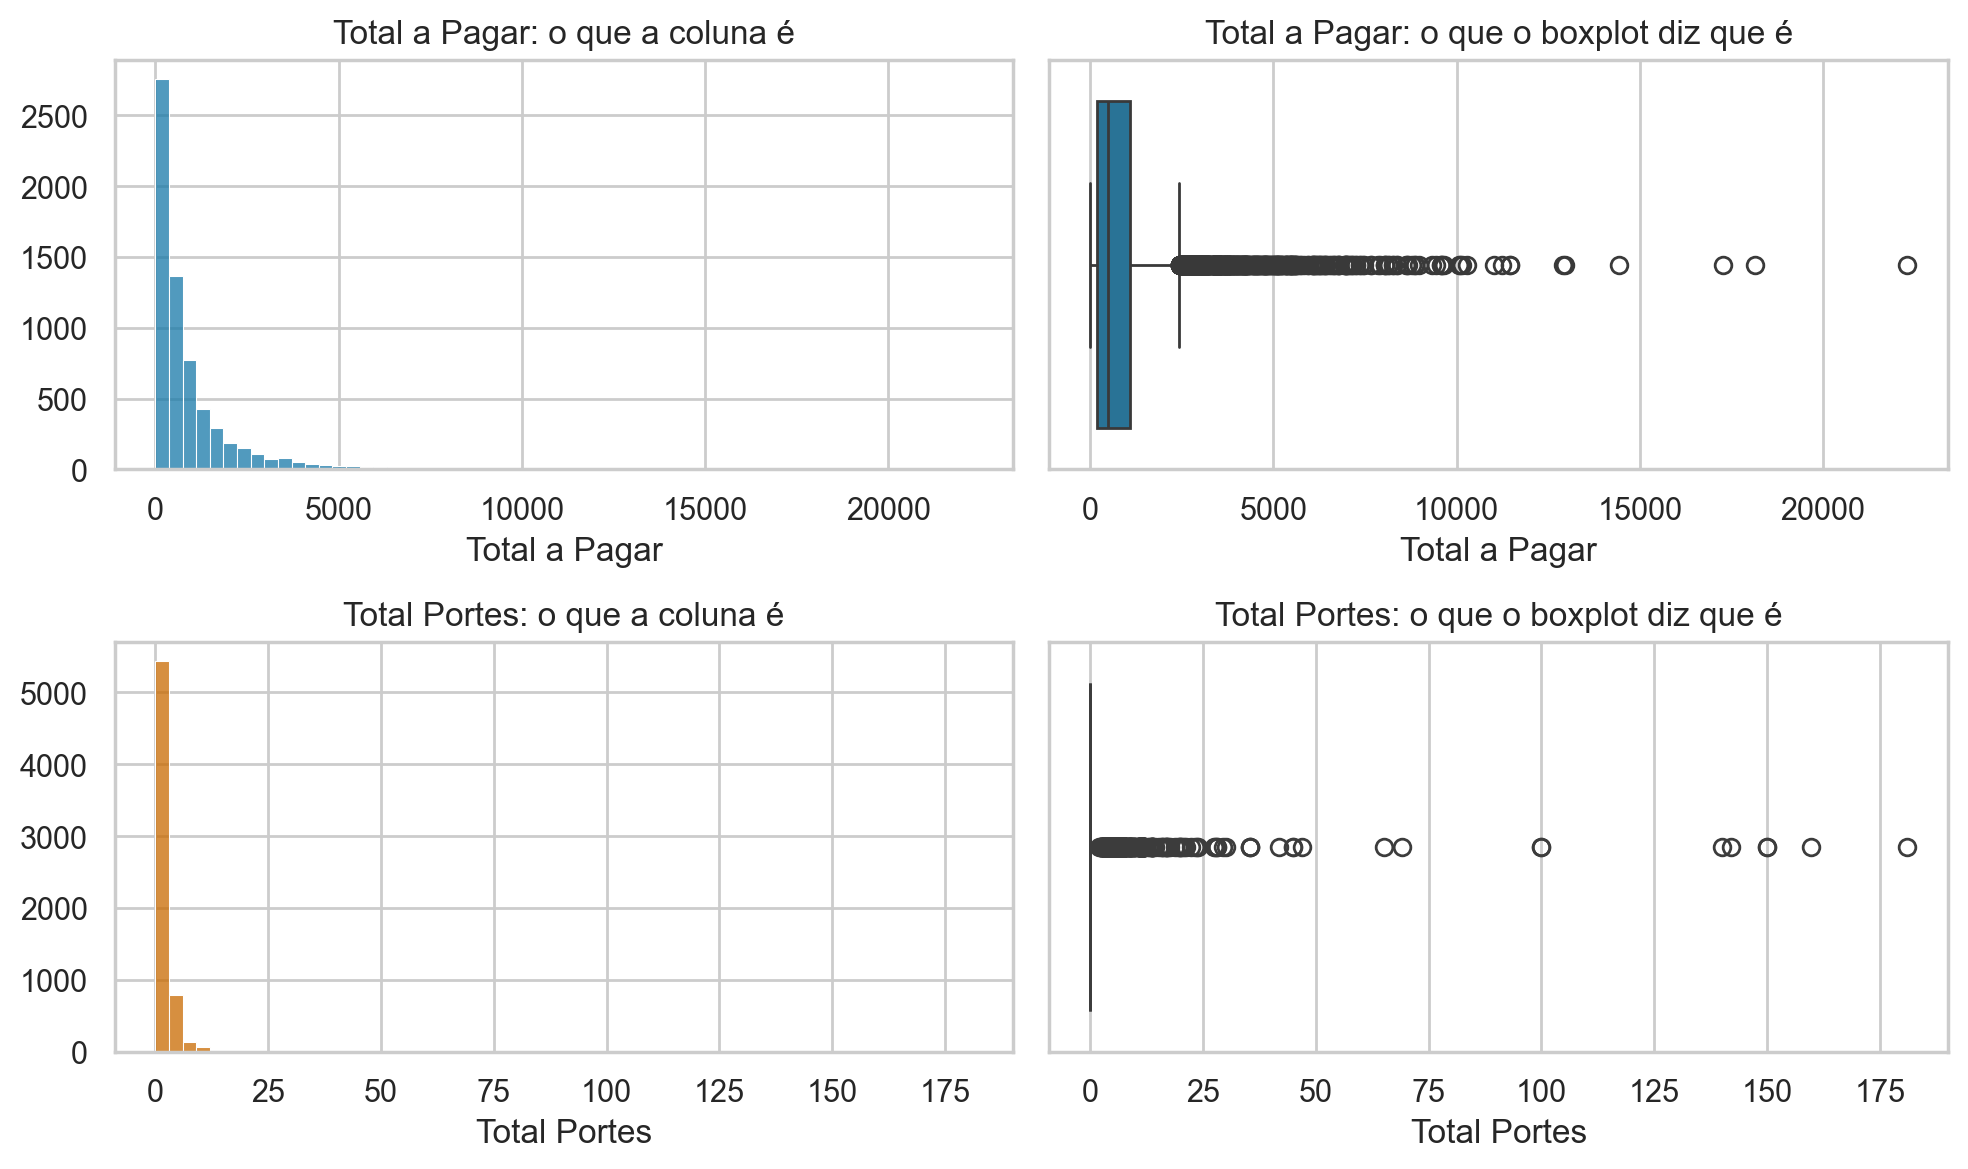

In [26]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)
for (column, colour), row in zip([("Total a Pagar", PLOT_BLUE), ("Total Portes", PLOT_ORANGE)],
                                 axes):
    sns.histplot(view[column].dropna(), bins=60, color=colour, ax=row[0])
    sns.boxplot(x=view[column].dropna(), color=colour, ax=row[1])
    row[0].set(title=f"{column}: o que a coluna é", ylabel="")
    row[1].set(title=f"{column}: o que o boxplot diz que é")
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">

**Quase todas as colunas monetárias e de contagem são muito assimétricas à direita.** A média chega a 1.9-2.9 vezes a mediana nos valores da compra e no histórico (`Total a Pagar` 926 vs 477, `prior_total_spend` 18,908 vs 6,754), e a assimetria passa de 3 em 25 das 29 numéricas. Em `log1p` as distribuições ficam aproximadamente simétricas, o que sugere essa transformação antes de modelos sensíveis à escala.

**A regra do boxplot inverte-se nas colunas com um pico em zero.** `Total Portes` é 83.7% zeros, por isso Q1 = Q3 = 0, o IQR é 0 e a regra assinala **todas** as 1,053 compras com portes (16.3% do ficheiro). O mesmo acontece em `Total Desc_ Global` (98.3% zeros) e, em menor grau, em `spend_30d` e `purchase_count_30d` (67% zeros). Aqui a regra mede quantos valores são diferentes de zero, não quantos são anómalos.

Nas colunas com "meio", a regra assinala 5-10% das linhas, que correspondem a clientes grandes e não a erros (os erros já foram tratados na secção 6). Remover estas linhas tiraria do treino exatamente os clientes mais ativos. As alternativas (manter, `log1p`, winsorizar) serão comparadas no pré-processamento.

</div>

# <font color='#1779A8'>9. Variáveis categóricas</font> <a class="anchor" id="categorical"></a>
[Voltar ao índice](#toc)

__Passo 22:__ Para cada categórica: número de níveis, níveis raros (menos de 1% das
linhas) e taxa de recompra por nível. A taxa de um nível com poucas linhas é uma
estimativa instável, por isso aparece sempre ao lado do número de linhas.

In [27]:
rare_share = 0.01
cat_overview = pd.DataFrame({
    "níveis": view[categorical].nunique(),
    "% do nível dominante": (100 * view[categorical].apply(
        lambda s: s.value_counts(normalize=True).iloc[0])).round(1),
    "níveis raros (<1%)": view[categorical].apply(
        lambda s: (s.value_counts(normalize=True) < rare_share).sum()),
    "% faltas": (100 * view[categorical].isna().mean()).round(2),
}).sort_values("níveis")
cat_overview

,níveis,% do nível dominante,níveis raros (<1%),% faltas
warehouse,2,99.7,1,3.01
document_series,3,42.3,0,0.00
commercial_zone,5,96.8,3,0.00
payment_type,9,72.8,5,3.01
salesperson,9,64.6,4,3.00
transport_method,80,17.8,59,3.03


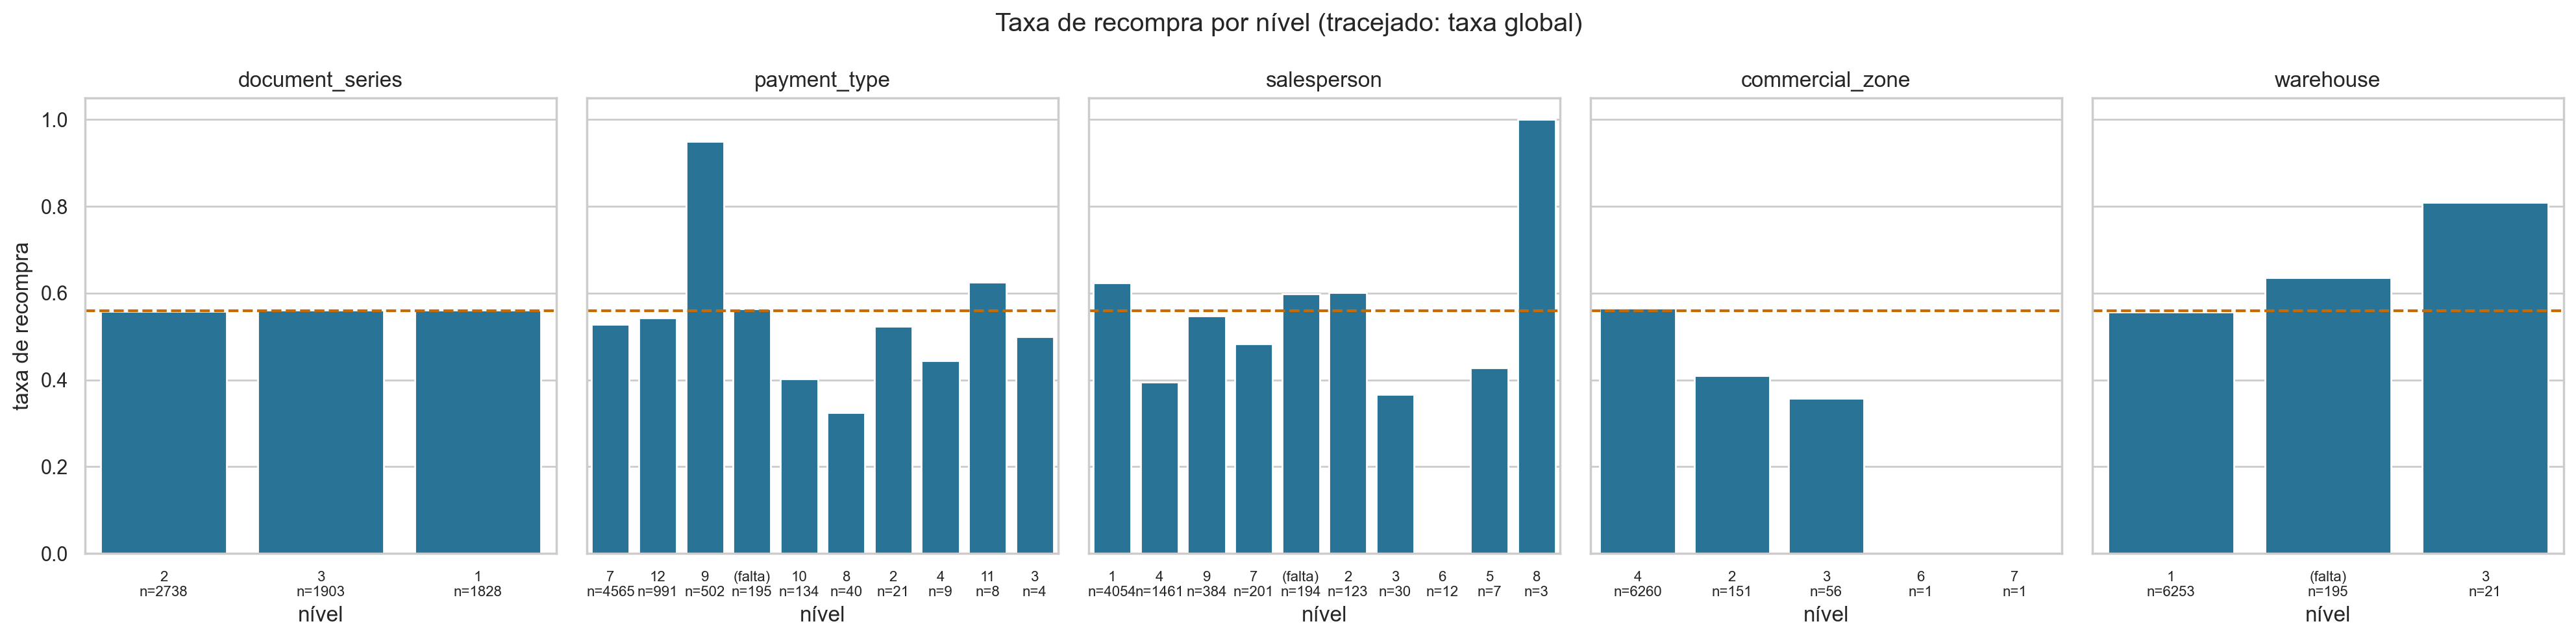

In [28]:
low_card = ["document_series", "payment_type", "salesperson", "commercial_zone", "warehouse"]
fig, axes = plt.subplots(1, len(low_card), figsize=(20, 5), sharey=True)
for column, ax in zip(low_card, axes):
    rates = (view.assign(**{column: view[column].fillna("(falta)")})
             .groupby(column)[TARGET].agg(["size", "mean"])
             .sort_values("size", ascending=False))
    # Rótulo: o número do nível e, por baixo, quantas linhas tem.
    codes = rates.index.str.replace(r"^.* (\d+)$", r"\1", regex=True)
    labels = [f"{code}\nn={n}" for code, n in zip(codes, rates["size"])]
    sns.barplot(x=labels, y=rates["mean"].to_numpy(), color=PLOT_BLUE, ax=ax)
    ax.tick_params(axis="x", labelsize=8)
    ax.axhline(view[TARGET].mean(), color=PLOT_ORANGE, ls="--")
    ax.set(title=column, xlabel="nível", ylabel="taxa de recompra" if ax is axes[0] else "")
plt.suptitle("Taxa de recompra por nível (tracejado: taxa global)")
plt.tight_layout()
plt.show()

__Passo 23:__ `transport_method` tem demasiados níveis para um gráfico de barras.
Mostra-se a distribuição das contagens por nível e a taxa de recompra dos níveis
mais frequentes.

In [29]:
transport_counts = view["transport_method"].value_counts()
print(f"{len(transport_counts)} níveis; {(transport_counts < 0.01 * len(view)).sum()}"
      f" com menos de 1% das linhas; {(transport_counts < 10).sum()} com menos de 10 linhas")
print(f"os 10 níveis mais frequentes cobrem {100 * transport_counts.head(10).sum() / view['transport_method'].notna().sum():.1f}%"
      " das linhas preenchidas")
(view.groupby("transport_method").agg(linhas=(TARGET, "size"), taxa=(TARGET, "mean"),
                                       clientes=("customer_id", "nunique"))
 .sort_values("linhas", ascending=False).head(10).round(3).T)

80 níveis; 59 com menos de 1% das linhas; 40 com menos de 10 linhas
os 10 níveis mais frequentes cobrem 66.4% das linhas preenchidas


transport_method,Maybe Tomorrow Delivery 72,Maybe Tomorrow Delivery 61,Maybe Tomorrow Delivery 73,Maybe Tomorrow Delivery 59,Maybe Tomorrow Delivery 80,Maybe Tomorrow Delivery 71,Maybe Tomorrow Delivery 40,Maybe Tomorrow Delivery 11,Maybe Tomorrow Delivery 53,Maybe Tomorrow Delivery 47
linhas,1119.000,627.000,445.000,373.000,319.000,301.000,257.000,253.00,247.000,222.000
taxa,0.493,0.601,0.494,0.493,0.646,0.545,0.533,0.98,0.664,0.545
clientes,137.000,127.000,39.000,45.000,82.000,36.000,37.000,2.00,102.000,71.000


__Passo 24:__ `document_series` não tem nenhuma relação aparente com o target. O que
é que a série do documento mede? Cruzá-la com o ano da compra.

In [30]:
pd.concat([
    pd.crosstab(train_dates.dt.year.astype("Int64"), train["document_series"]),
    pd.crosstab(test_dates.dt.year, test["document_series"]).add_prefix("teste: "),
], axis=1).fillna(0).astype(int)

document_series,Ctrl Z Series 1,Ctrl Z Series 2,Ctrl Z Series 3,teste: Ctrl Z Series 2
purchase_date,,,,
2015,0,0,335,0
2016,0,0,420,0
2017,281,0,389,0
2018,387,0,329,0
2019,397,0,249,0
2020,532,0,138,0
2021,231,508,43,0
2022,0,628,0,0
2023,0,767,0,0


<div class="alert alert-block alert-warning">

**Duas categóricas têm quase nenhuma informação, uma tem demasiada, e uma mede o tempo.**

- **`warehouse` (99.7% num nível) e `commercial_zone` (96.8%)** são quase constantes no treino. Os poucos níveis restantes têm dezenas de linhas, e as respetivas taxas de recompra são estimativas instáveis.
- **`payment_type` e `salesperson`** têm 9 níveis cada, com diferenças de taxa de recompra visíveis nos níveis com mais linhas; os 4-5 níveis raros (< 1%) devem ser agrupados num nível "outros" antes de codificar.
- **`transport_method` tem 80 níveis, 59 deles com menos de 1% das linhas.** O caso extremo é o nível 11: 253 linhas, 98% de recompra, e **só 2 clientes**. Um nível destes não descreve um método de transporte, identifica um cliente. É preciso agrupar os níveis raros, ou usar uma codificação por frequência, para que o modelo não memorize clientes.
- **`document_series` mede o tempo, não a compra.** A série 3 cobre 2015-2021, a 1 cobre 2017-2021 e a 2 começa em 2021; **o teste é 100% série 2.** A taxa de recompra é igual nas três (V = 0.003). No teste, a coluna é constante e não carrega informação nenhuma.

</div>

# <font color='#1779A8'>10. Relação com o target</font> <a class="anchor" id="relevance"></a>
[Voltar ao índice](#toc)

__Passo 25:__ Uma medida de associação por coluna, escolhida pelo tipo (como na
semana 4): **|r| point-biserial** para uma numérica, **V de Cramér** para uma
categórica. Ambas estão em $[0, 1]$, por isso entram na mesma tabela.

A secção 8 mostrou que as numéricas são muito assimétricas, e um r calculado na
escala original é decidido pela cauda. Por isso, como na semana 4, o r é calculado
duas vezes: na escala original e depois de `log1p`. `random_noise` não tem cauda
nem domínio positivo, e fica na escala original.

In [31]:
# A mesma vista em log1p, usada para todas as correlações daqui em diante.
logged = [c for c in numeric if c != "random_noise"]
log_view = view[numeric].copy()
log_view[logged] = np.log1p(log_view[logged].clip(lower=0))

relevance = []
for column in numeric:
    rows = view[column].notna()
    r_raw, _ = pointbiserialr(view.loc[rows, TARGET], view.loc[rows, column])
    r_log, p = pointbiserialr(view.loc[rows, TARGET], log_view.loc[rows, column])
    relevance.append({"coluna": column, "tipo": "numérica", "r (original)": r_raw,
                      "r (log1p)": r_log, "p": p, "linhas": int(rows.sum())})
for column in categorical:
    statistic, p, v_cramer, min_expected = cramers_v(view[column].fillna("(falta)"),
                                                     view[TARGET])
    relevance.append({"coluna": column, "tipo": "categórica", "V de Cramér": v_cramer,
                      "p": p, "menor esperado": min_expected, "linhas": len(view)})
relevance = pd.DataFrame(relevance).set_index("coluna")
relevance["associação"] = relevance["r (log1p)"].abs().fillna(relevance["V de Cramér"])
relevance = relevance.sort_values("associação", ascending=False)
relevance.round(4)

,tipo,r (original),r (log1p),p,linhas,V de Cramér,menor esperado,associação
coluna,,,,,,,,
purchase_count_365d,numérica,0.3403,0.4240,0.0000,6469,NaN,NaN,0.4240
purchase_count_180d,numérica,0.3342,0.4066,0.0000,6469,NaN,NaN,0.4066
purchase_count_90d,numérica,0.3279,0.3964,0.0000,6469,NaN,NaN,0.3964
prior_mean_gap_days,numérica,-0.2388,-0.3888,0.0000,5210,NaN,NaN,0.3888
spend_90d,numérica,0.2689,0.3508,0.0000,6469,NaN,NaN,0.3508
prior_purchase_count,numérica,0.2988,0.3460,0.0000,6469,NaN,NaN,0.3460
spend_180d,numérica,0.3010,0.3170,0.0000,6469,NaN,NaN,0.3170
prior_std_gap_days,numérica,-0.2045,-0.3156,0.0000,5056,NaN,NaN,0.3156
spend_365d,numérica,0.1868,0.3081,0.0000,6244,NaN,NaN,0.3081


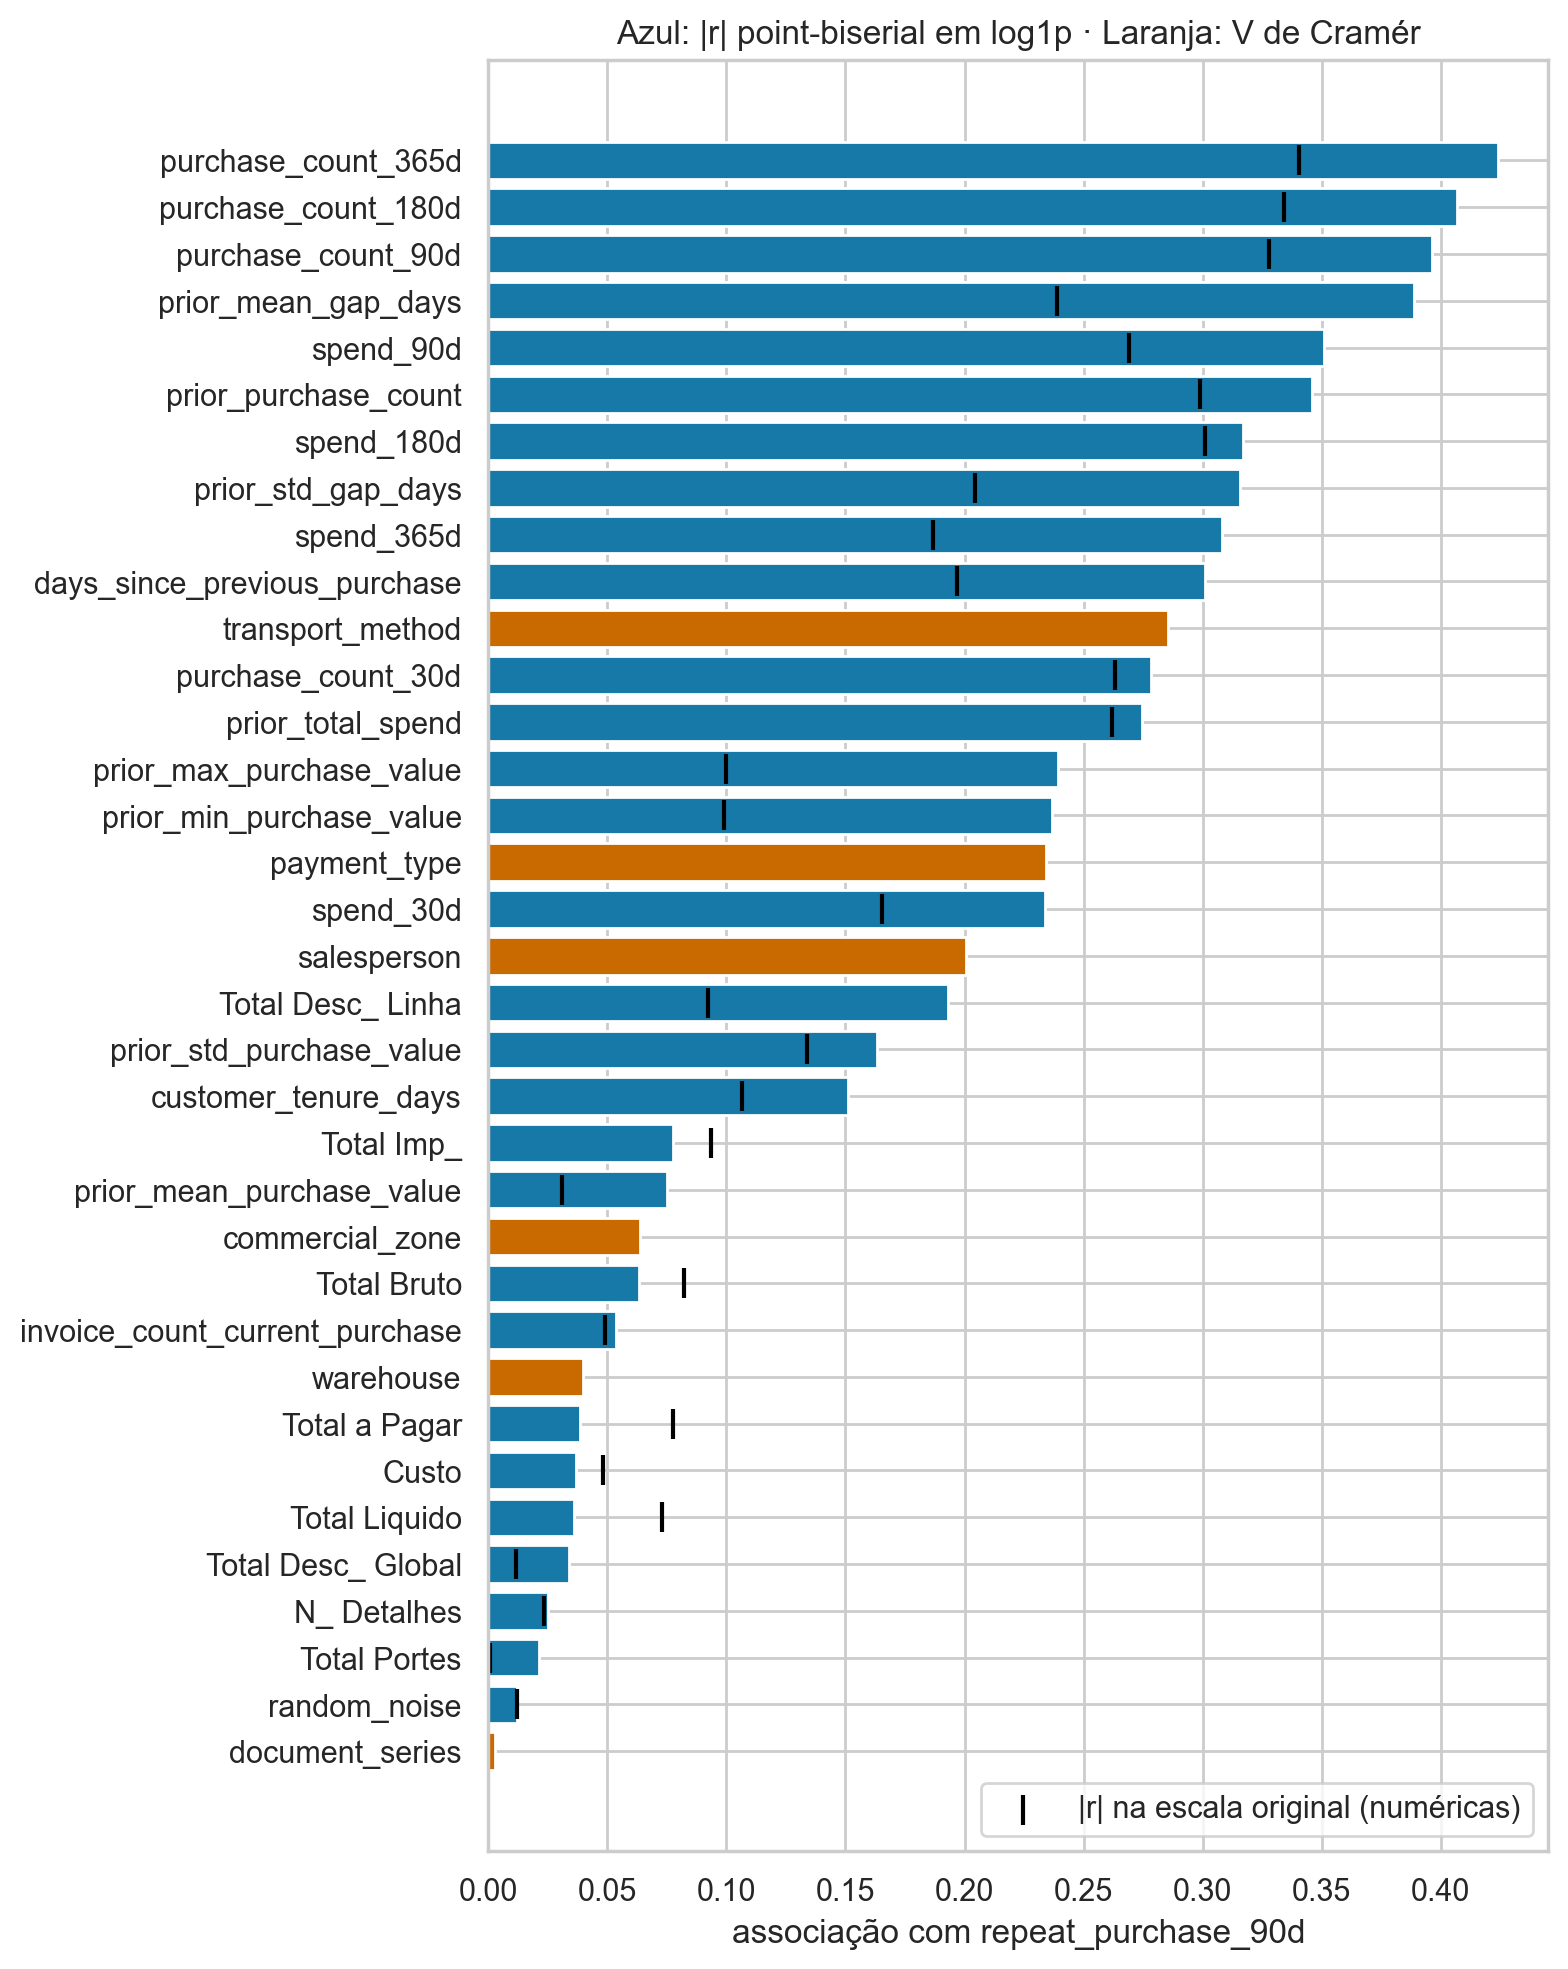

In [32]:
fig, ax = plt.subplots(figsize=(8, 10))
colours = [PLOT_BLUE if t == "numérica" else PLOT_ORANGE for t in relevance["tipo"]]
ax.barh(relevance.index[::-1], relevance["associação"][::-1], color=colours[::-1])
ax.scatter(relevance["r (original)"].abs()[::-1], relevance.index[::-1], color="black",
           marker="|", s=120, label="|r| na escala original (numéricas)")
ax.set(xlabel="associação com repeat_purchase_90d",
       title="Azul: |r| point-biserial em log1p · Laranja: V de Cramér")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

__Passo 26:__ As seis numéricas mais associadas, por classe. A escala `log1p`
deixa ver a diferença entre medianas que a cauda esconderia.

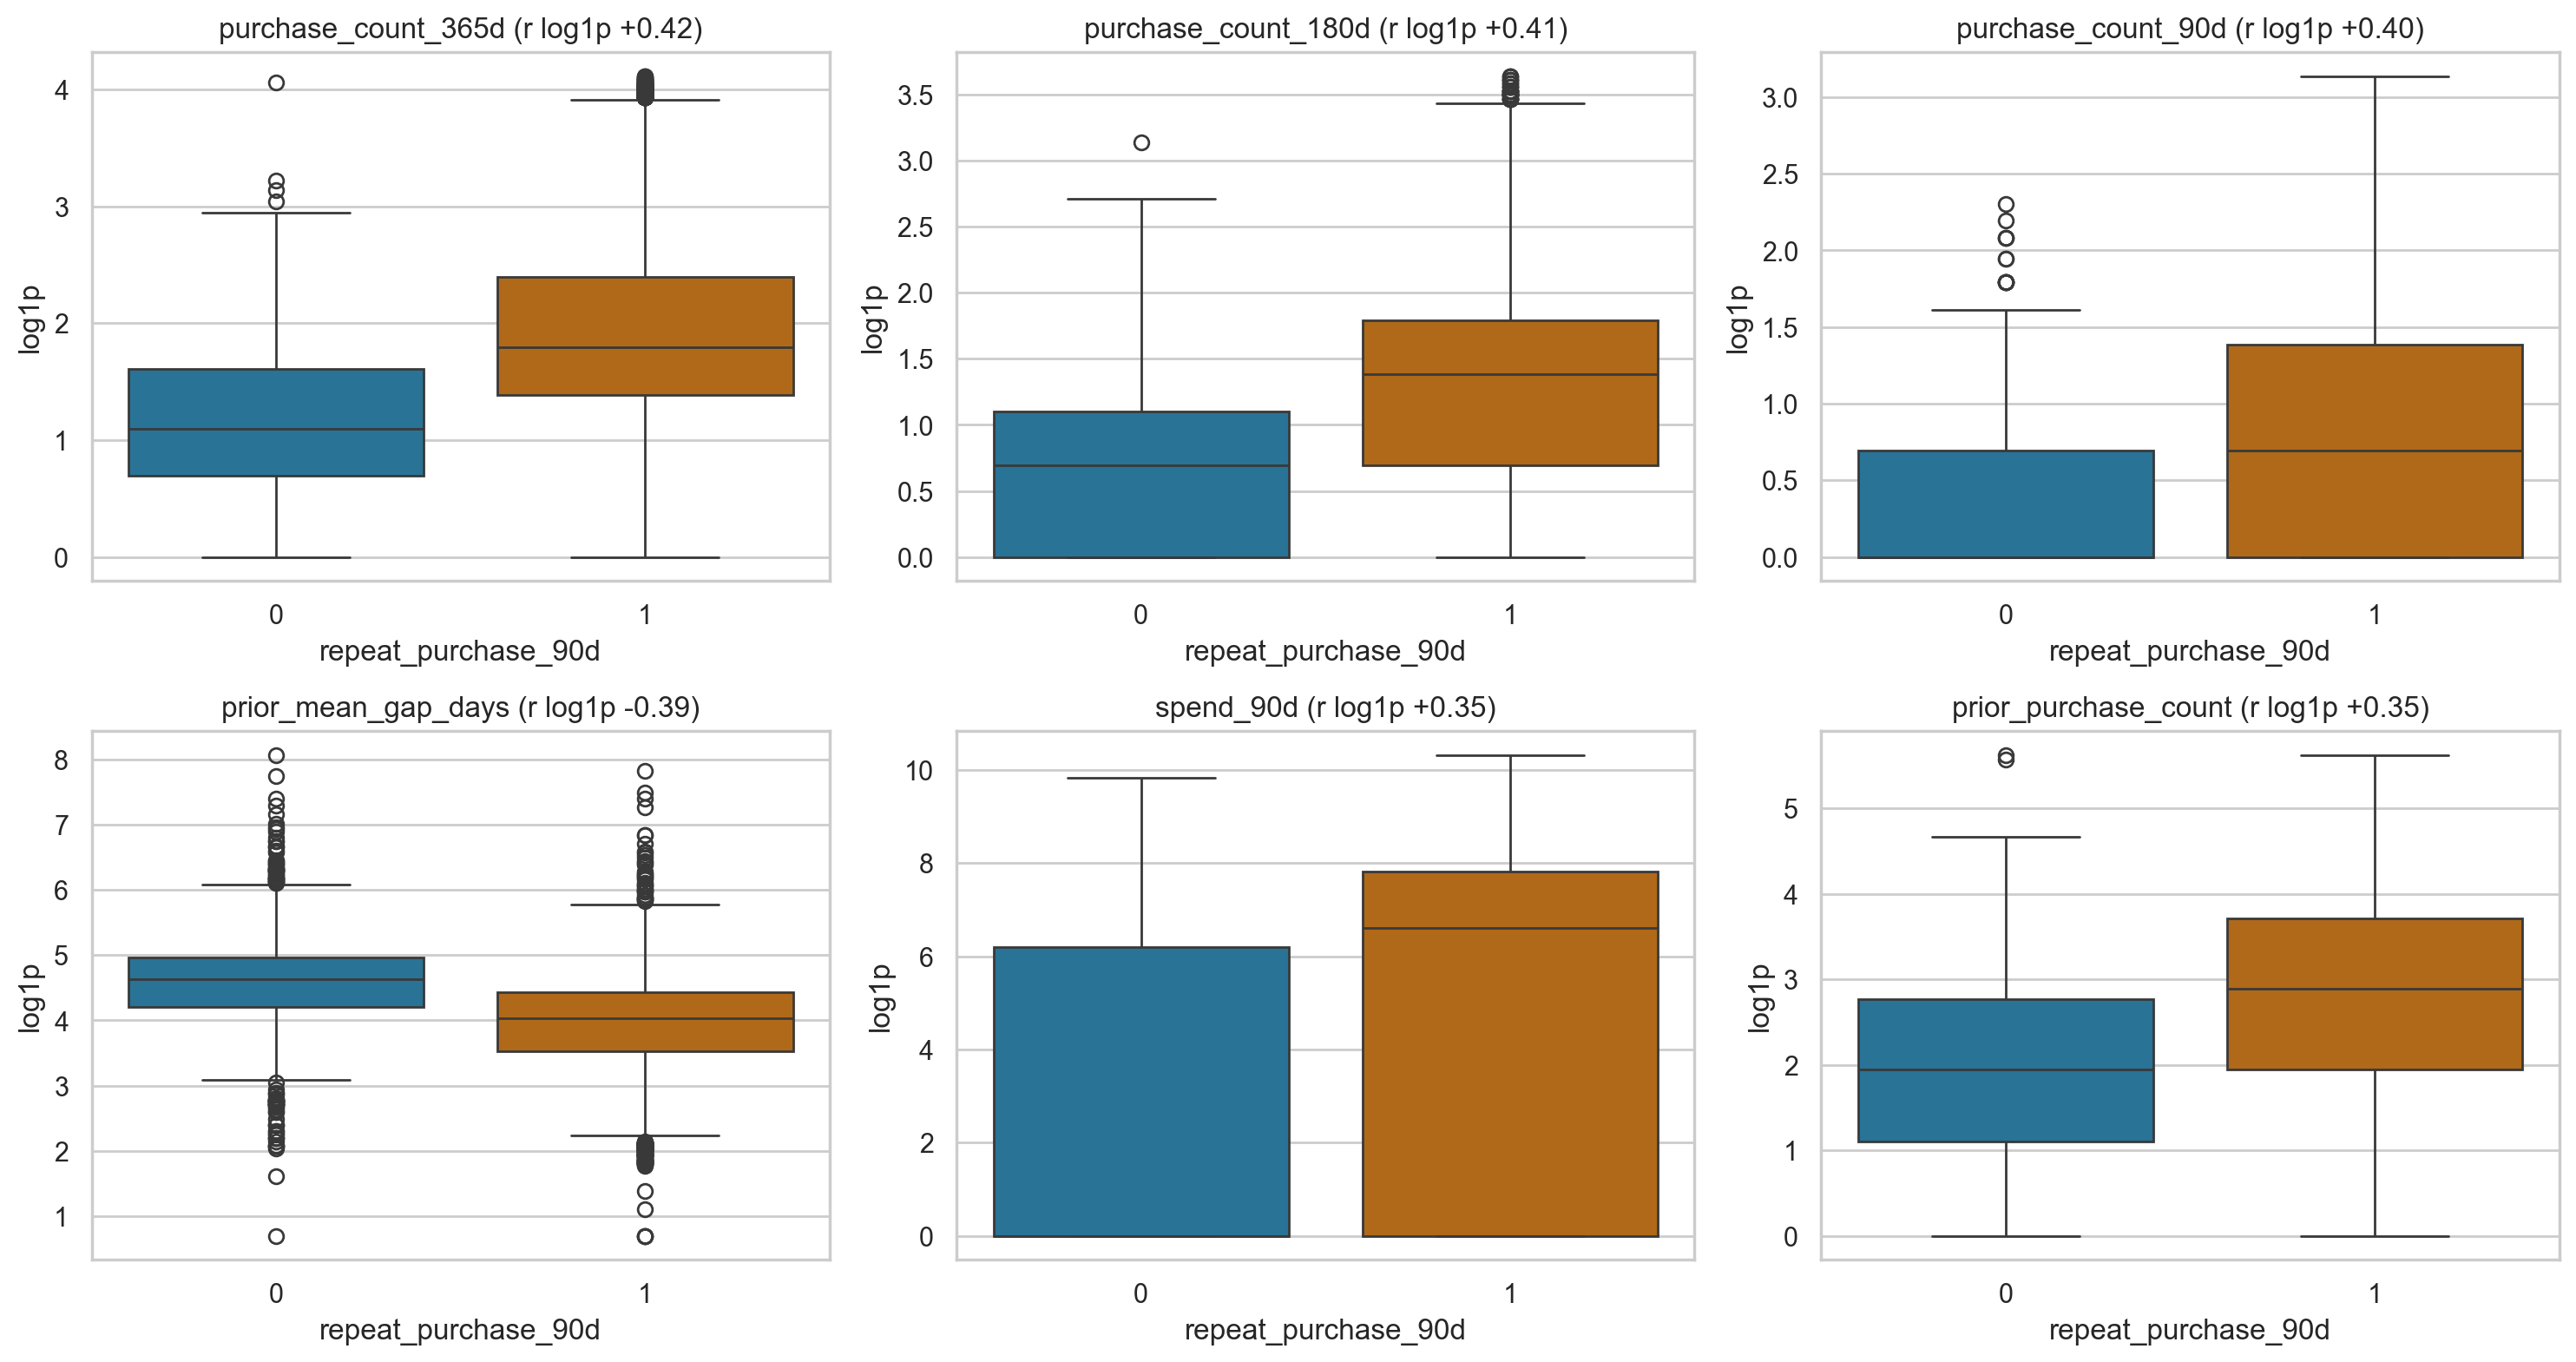

In [33]:
top_numeric = relevance[relevance["tipo"] == "numérica"].index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(top_numeric, axes.ravel()):
    sns.boxplot(x=view[TARGET], y=log_view[column], hue=view[TARGET],
                palette=CLASS_PALETTE, legend=False, ax=ax)
    ax.set(title=f"{column} (r log1p {relevance.loc[column, 'r (log1p)']:+.2f})",
           xlabel="repeat_purchase_90d", ylabel="log1p")
plt.tight_layout()
plt.show()

__Passo 27:__ Recência e frequência em conjunto: a taxa de recompra por decil de
`days_since_previous_purchase` e por número de compras nos últimos 365 dias.

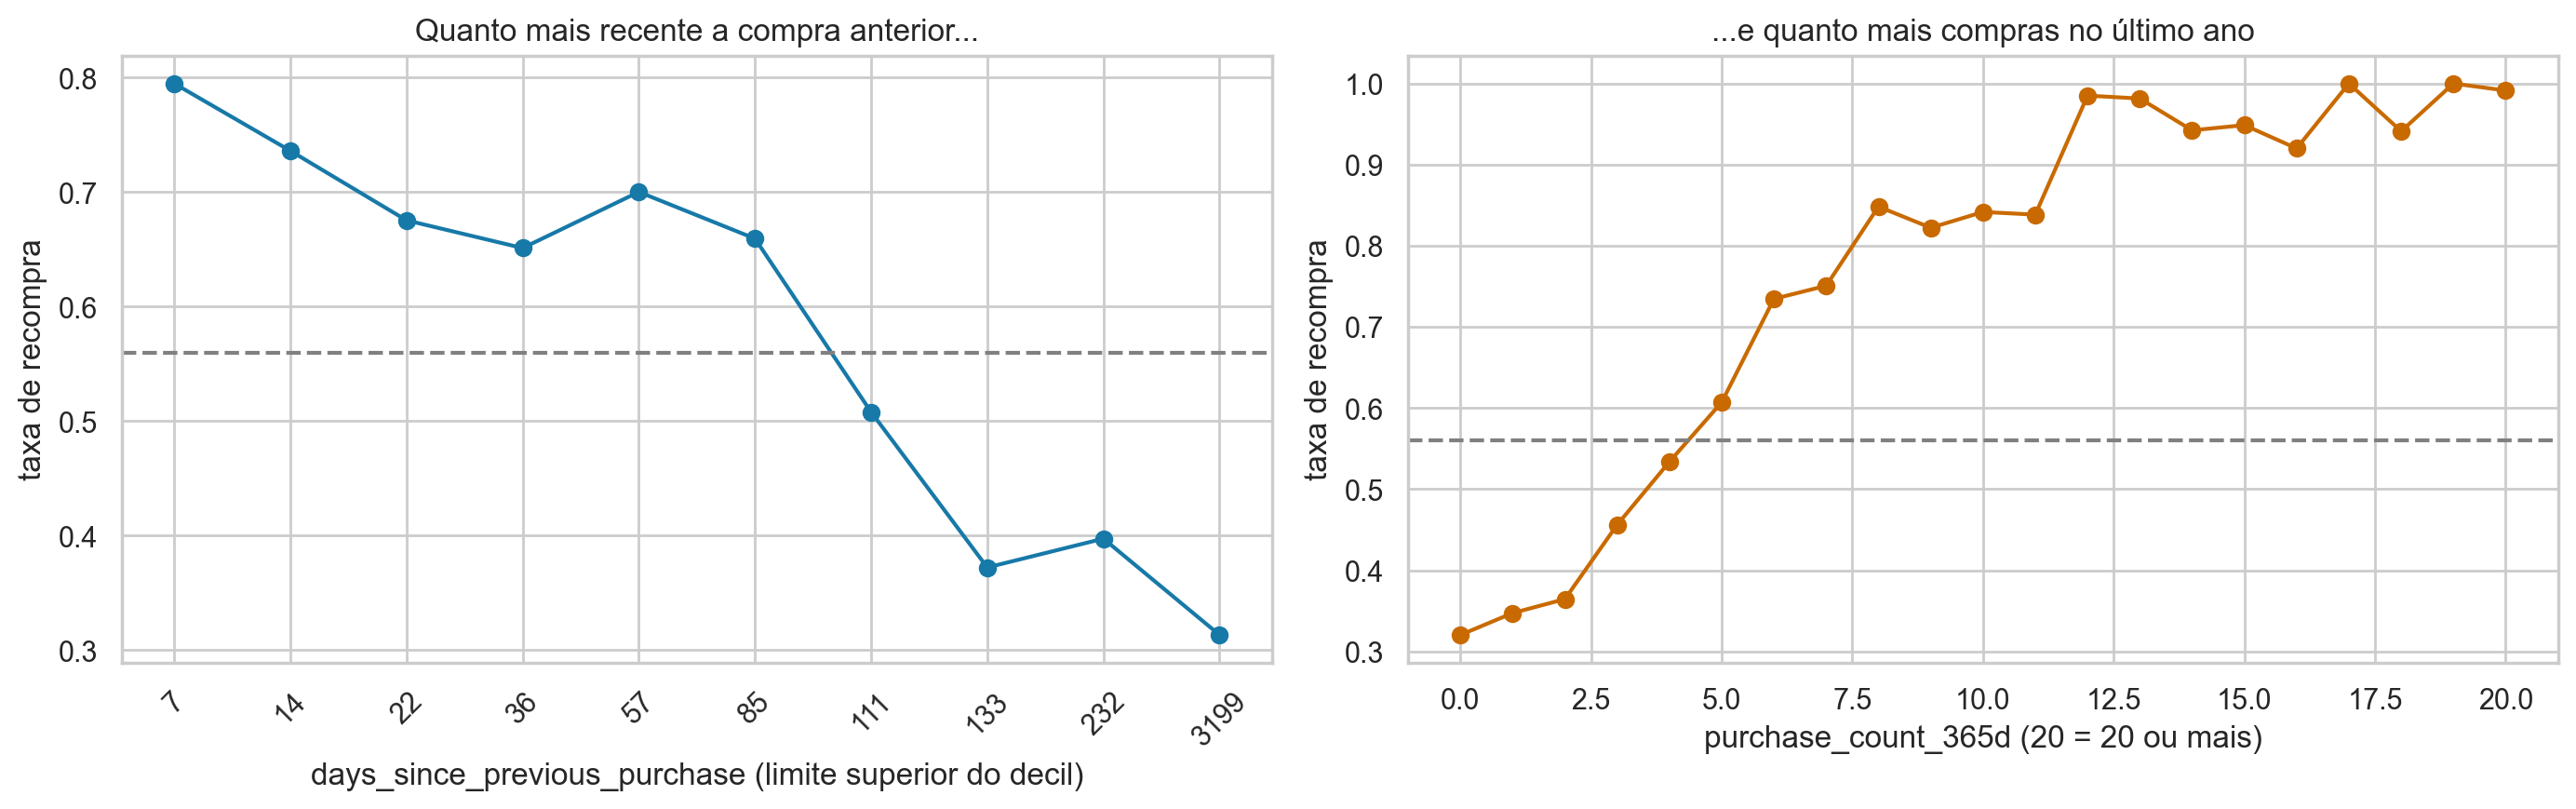

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
recency_decile = pd.qcut(view["days_since_previous_purchase"], 10, duplicates="drop")
rate = view.groupby(recency_decile, observed=True)[TARGET].mean()
axes[0].plot(range(len(rate)), rate.values, marker="o", color=PLOT_BLUE)
axes[0].set_xticks(range(len(rate)), [f"{i.right:.0f}" for i in rate.index], rotation=45)
axes[0].set(xlabel="days_since_previous_purchase (limite superior do decil)",
            ylabel="taxa de recompra", title="Quanto mais recente a compra anterior...")

freq = view["purchase_count_365d"].clip(upper=20)
rate = view.groupby(freq)[TARGET].agg(["mean", "size"])
axes[1].plot(rate.index, rate["mean"], marker="o", color=PLOT_ORANGE)
axes[1].set(xlabel="purchase_count_365d (20 = 20 ou mais)", ylabel="taxa de recompra",
            title="...e quanto mais compras no último ano")
for ax in axes:
    ax.axhline(view[TARGET].mean(), color="grey", ls="--")
plt.tight_layout()
plt.show()

__Passo 28:__ `random_noise`. O enunciado pede para avaliar se contém informação,
por isso o nome não chega como argumento: compara-se a distribuição nas duas
classes e testa-se a associação.

random_noise: média -0.022, desvio-padrão 1.001, skew 0.054
point-biserial r = -0.0120 (p = 0.335)
máxima |correlação| com outra feature (log1p): 0.0259


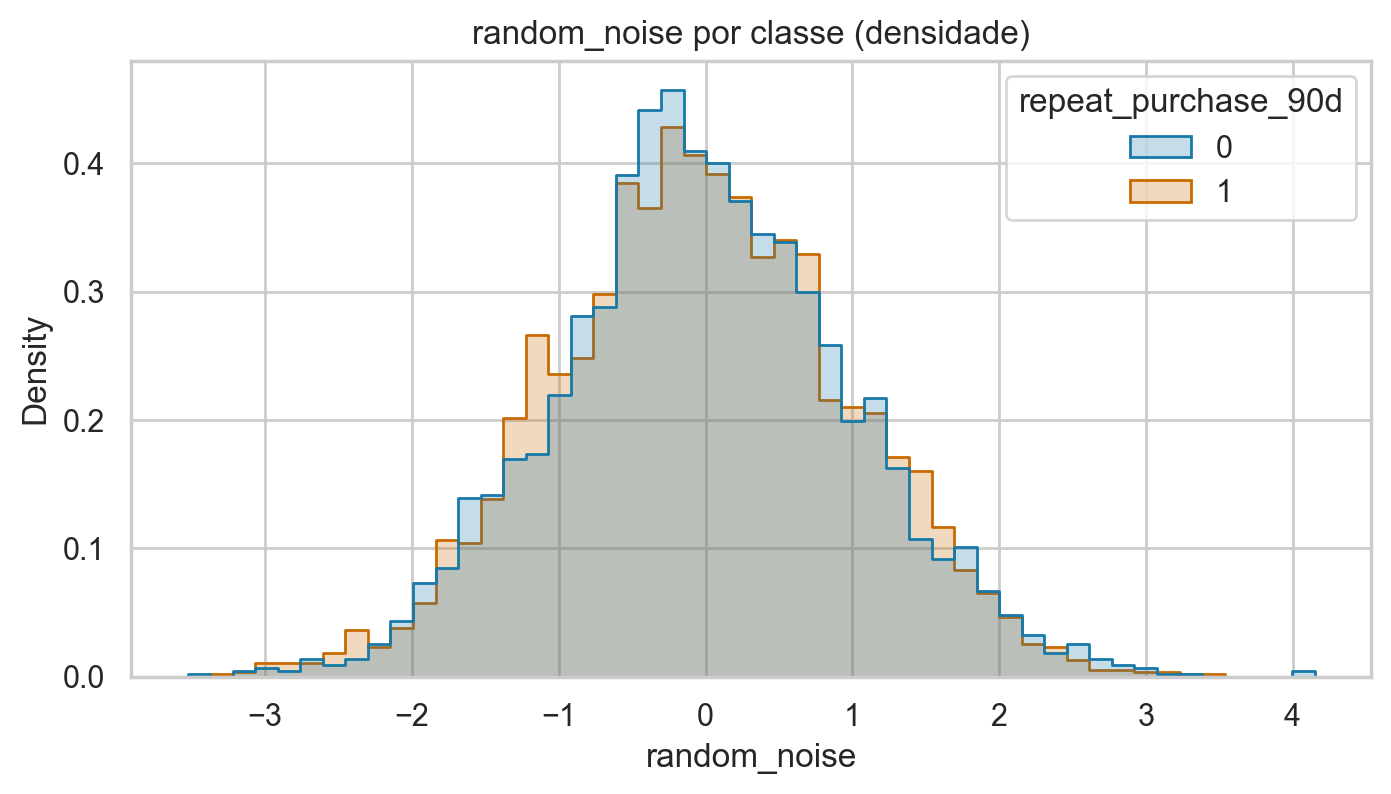

In [35]:
r, p = pointbiserialr(view[TARGET], view["random_noise"])
print(f"random_noise: média {view['random_noise'].mean():.3f}, desvio-padrão"
      f" {view['random_noise'].std():.3f}, skew {view['random_noise'].skew():.3f}")
print(f"point-biserial r = {r:.4f} (p = {p:.3f})")
print("máxima |correlação| com outra feature (log1p):",
      log_view.corr()["random_noise"].drop("random_noise").abs().max().round(4))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=view, x="random_noise", hue=TARGET, palette=CLASS_PALETTE,
             stat="density", common_norm=False, bins=50, element="step", ax=ax)
ax.set(title="random_noise por classe (densidade)")
plt.show()

<div class="alert alert-block alert-success">

**A frequência recente é o sinal mais forte.** `purchase_count_365d`, `_180d` e `_90d` lideram (|r| 0.40-0.42 em log1p), seguidas do gasto móvel e de `prior_purchase_count`. Os gráficos de recência e frequência mostram uma relação monótona: a taxa de recompra desce de forma regular à medida que a compra anterior fica mais distante (de 0.80 no primeiro decil para 0.31 no último) e sobe com o número de compras no último ano (de 0.32 sem compras para perto de 1 a partir de 12). É o padrão RFM (recência, frequência, valor) clássico.

**O `log1p` muda a leitura de várias colunas.** `prior_mean_gap_days` passa de |r| 0.24 na escala original para 0.39 em log1p, `prior_max_purchase_value` de 0.10 para 0.24 e `Total Desc_ Linha` de 0.09 para 0.19. Na escala original, a cauda de cada uma destas colunas escondia a relação. É um argumento direto para aplicar `log1p` no pré-processamento.

**Entre as categóricas, `transport_method` (V 0.29) e `payment_type` (0.23)** são as mais associadas, mas o V de `transport_method` está inflacionado pelos níveis que identificam clientes (secção 9), e várias contagens esperadas ficam abaixo de 5, o que torna os p-values ilegíveis.

**O valor da compra atual quase não importa:** todo o bloco monetário tem |r| < 0.08 em log1p, e `Total Portes`, `Total Desc_ Global`, `N_ Detalhes` e `document_series` têm associação praticamente nula.

**`random_noise` é ruído:** distribuição normal padrão (média -0.02, desvio-padrão 1.00, skew 0.05), r = -0.012 com p = 0.335, e nenhuma correlação acima de 0.03 com outra feature. As duas classes têm a mesma densidade. Fica como candidata a remoção, a confirmar na seleção de features.

</div>

# <font color='#1779A8'>11. Relações multivariadas e redundância</font> <a class="anchor" id="multivariate"></a>
[Voltar ao índice](#toc)

__Passo 29:__ Correlação entre todas as numéricas, calculada na vista `log1p` do
passo anterior: na escala original, as colunas são tão assimétricas que o r seria
decidido por meia dúzia de valores na cauda.

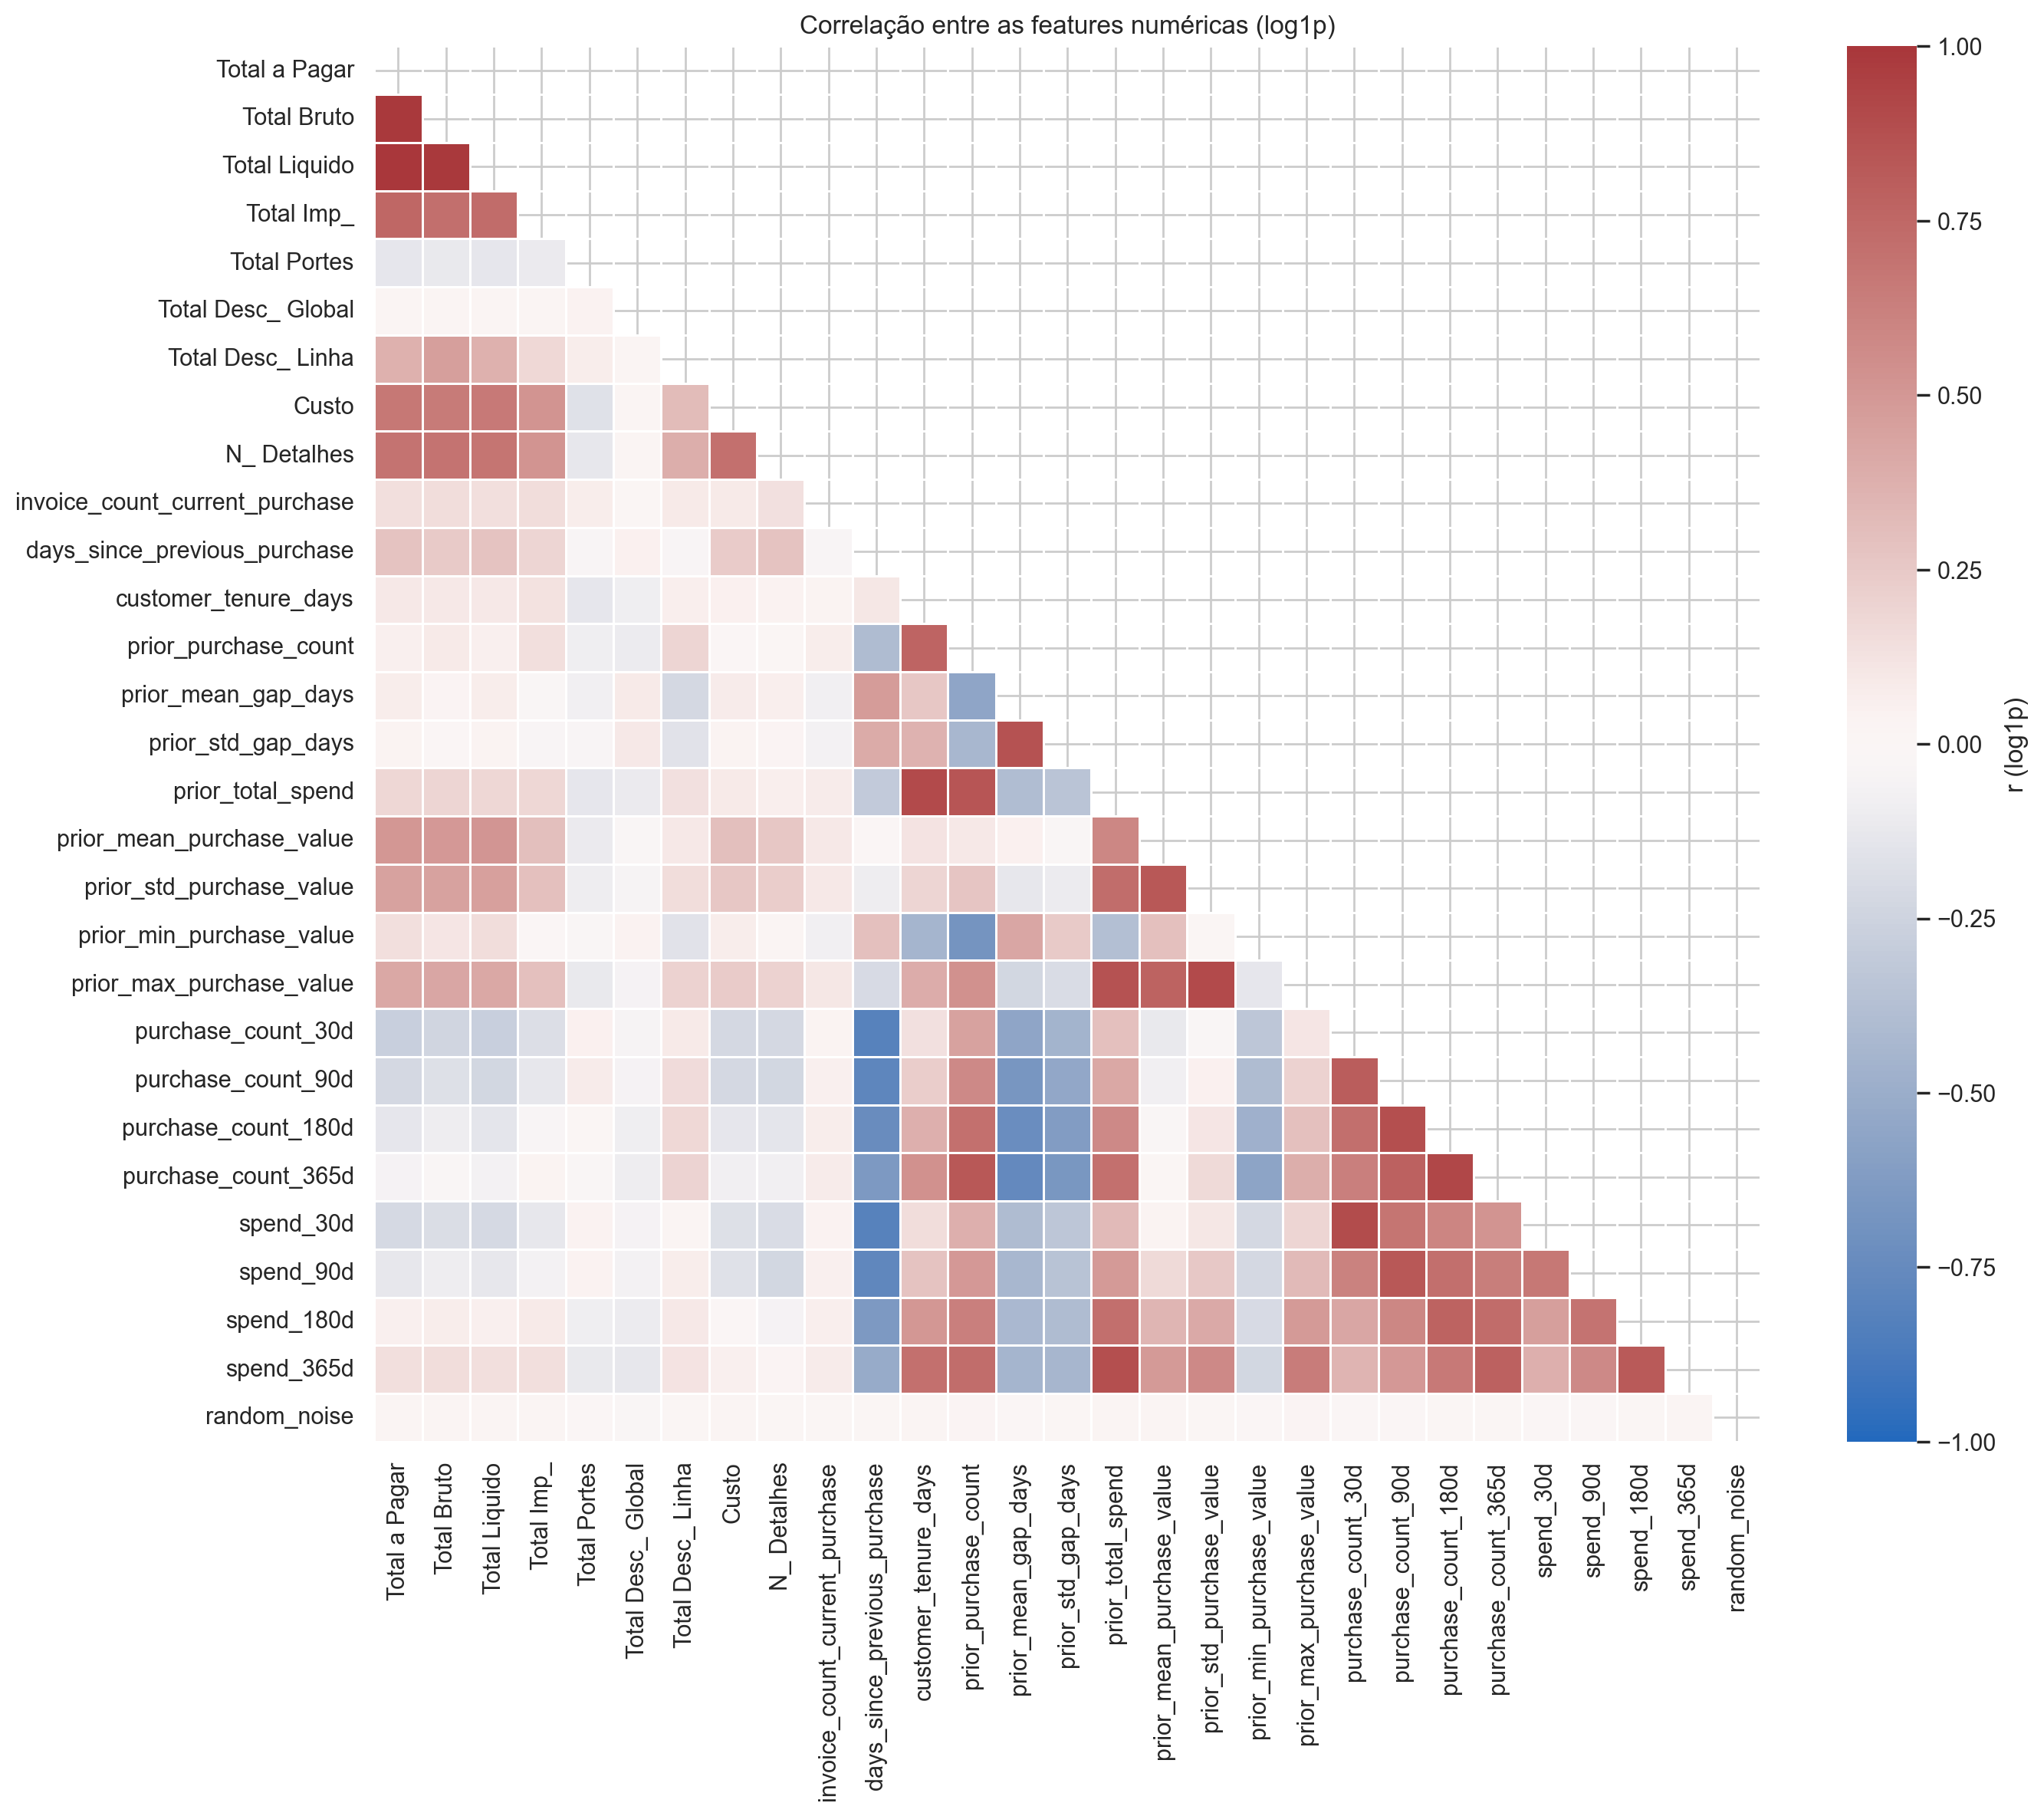

In [36]:
correlation = log_view.corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(correlation, mask=np.triu(np.ones_like(correlation, dtype=bool)), cmap="vlag",
            vmin=-1, vmax=1, center=0, linewidths=0.5, cbar_kws={"label": "r (log1p)"},
            ax=ax)
ax.set(title="Correlação entre as features numéricas (log1p)")
plt.tight_layout()
plt.show()

__Passo 30:__ Os pares com $|r| \geq 0.9$: candidatos a redundância, a resolver na
seleção de features.

In [37]:
pairs = (correlation.where(np.triu(np.ones_like(correlation, dtype=bool), k=1))
         .stack().rename("r (log1p)").to_frame())
pairs = pairs[pairs["r (log1p)"].abs() >= 0.9].sort_values("r (log1p)", key=abs,
                                                           ascending=False)
print(f"{len(pairs)} pares com |r| >= 0.9")
pairs.round(3)

6 pares com |r| >= 0.9


,,r (log1p)
Total a Pagar,Total Liquido,1.000
Total Bruto,Total Liquido,0.992
Total a Pagar,Total Bruto,0.991
purchase_count_180d,purchase_count_365d,0.917
customer_tenure_days,prior_total_spend,0.903
prior_std_purchase_value,prior_max_purchase_value,0.903


__Passo 31:__ Associação entre as categóricas (V de Cramér par a par), para ver se
alguma é praticamente outra com outro nome.

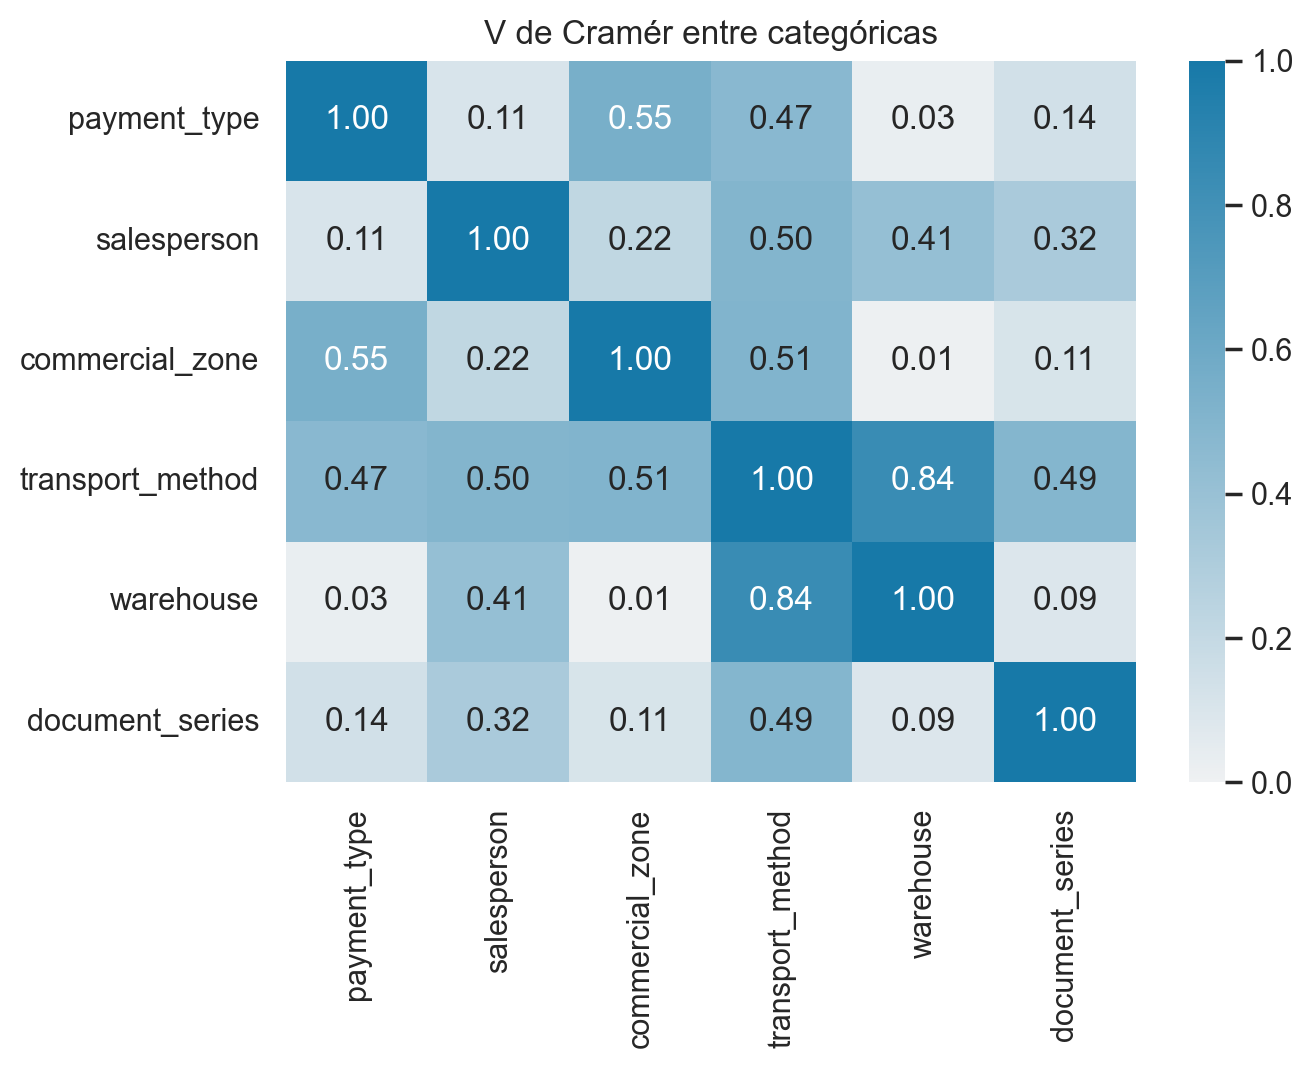

In [38]:
cat_assoc = pd.DataFrame(index=categorical, columns=categorical, dtype=float)
for a in categorical:
    for b in categorical:
        if a == b:
            cat_assoc.loc[a, b] = 1.0
            continue
        pair = view[[a, b]].dropna()
        cat_assoc.loc[a, b] = cramers_v(pair[a], pair[b])[2]

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cat_assoc, annot=True, fmt=".2f", vmin=0, vmax=1,
            cmap=sns.light_palette(PLOT_BLUE, as_cmap=True), ax=ax)
ax.set(title="V de Cramér entre categóricas")
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">

**Seis pares têm $|r| \geq 0.9$ em log1p**, e quase todos têm uma explicação construtiva:

- `Total a Pagar`, `Total Bruto` e `Total Liquido` (r 0.99-1.00): três medidas do mesmo valor, ligadas pelas identidades da secção 7.
- `purchase_count_180d` / `purchase_count_365d` (0.92): a janela de 180 dias está contida na de 365.
- `customer_tenure_days` / `prior_total_spend` (0.90): quanto mais antigo o cliente, mais gastou no total.
- `prior_std_purchase_value` / `prior_max_purchase_value` (0.90): o máximo puxa o desvio-padrão.

O heatmap mostra também **blocos**: as janelas móveis estão fortemente correlacionadas entre si, e o bloco monetário da compra atual quase não se correlaciona com o histórico. A seleção de features deve manter um representante por bloco redundante (o mais associado ao target) em vez de os manter todos.

Nas categóricas, nenhum par chega perto de 1: não há nenhuma coluna que seja apenas outra com outro nome.

</div>

# <font color='#1779A8'>12. Treino vs teste</font> <a class="anchor" id="shift"></a>
[Voltar ao índice](#toc)

O teste é um período posterior (secção 4). Um modelo só generaliza para lá se as
features tiverem distribuições parecidas nos dois lados. Olhar para o teste
**para descrever** não usa informação dele para ajustar nada.

__Passo 32:__ Comparar as medianas do treino e do teste, e a razão entre elas.

In [39]:
test_view = test.copy()
for column, rule in invalid_rules.items():
    test_view[column] = test_view[column].mask(rule(test_view[column]))

shift = pd.DataFrame({
    "mediana treino": view[logged].median(),
    "mediana teste": test_view[logged].median(),
})
shift["teste / treino"] = shift["mediana teste"] / shift["mediana treino"].replace(0, np.nan)
shift.dropna().sort_values("teste / treino", ascending=False).round(2).head(12)

,mediana treino,mediana teste,teste / treino
Total Desc_ Linha,13.13,77.08,5.87
prior_total_spend,6754.31,25186.53,3.73
customer_tenure_days,918.00,2662.00,2.90
prior_purchase_count,11.00,28.00,2.55
spend_90d,198.50,472.72,2.38
spend_365d,2426.60,5423.65,2.24
spend_180d,1117.68,2168.00,1.94
prior_max_purchase_value,1783.24,3198.00,1.79
Custo,152.54,226.34,1.48
Total Bruto,445.74,655.80,1.47


__Passo 33:__ Nas categóricas, o peso do nível dominante em cada lado, e os níveis
que aparecem no teste sem nunca terem aparecido no treino.

In [40]:
cat_shift = []
for column in categorical:
    dominant = view[column].value_counts().index[0]
    unseen = set(test_view[column].dropna()) - set(view[column].dropna())
    cat_shift.append({"categórica": column, "nível dominante no treino": dominant,
                      "% treino": 100 * (view[column] == dominant).mean(),
                      "% teste": 100 * (test_view[column] == dominant).mean(),
                      "níveis no teste ausentes do treino": len(unseen),
                      "linhas do teste nesses níveis": int(test_view[column].isin(unseen).sum())})
pd.DataFrame(cat_shift).set_index("categórica").round(1)

,nível dominante no treino,% treino,% teste,níveis no teste ausentes do treino,linhas do teste nesses níveis
categórica,,,,,
payment_type,Maybe Tomorrow Payment 7,70.6,65.3,3,3
salesperson,VLOOKUP Master 1,62.7,48.1,0,0
commercial_zone,Decorative Dashboard Zone 4,96.8,70.1,2,209
transport_method,Maybe Tomorrow Delivery 72,17.3,9.1,2,63
warehouse,Final Excel Warehouse 1,96.7,96.2,1,7
document_series,Ctrl Z Series 2,42.3,100.0,0,0


__Passo 34:__ Os clientes que voltam a aparecer no teste: como se comportavam no
treino, comparados com os restantes?

In [41]:
returning = view["customer_id"].isin(test["customer_id"])
pd.DataFrame({
    "linhas": [returning.sum(), (~returning).sum()],
    "clientes": [view.loc[returning, "customer_id"].nunique(),
                 view.loc[~returning, "customer_id"].nunique()],
    "taxa de recompra": [view.loc[returning, TARGET].mean(), view.loc[~returning, TARGET].mean()],
    "mediana de purchase_count_365d": [view.loc[returning, "purchase_count_365d"].median(),
                                       view.loc[~returning, "purchase_count_365d"].median()],
}, index=["clientes que estão no teste", "restantes"]).round(3)

,linhas,clientes,taxa de recompra,mediana de purchase_count_365d
clientes que estão no teste,3971,184,0.618,4.0
restantes,2498,423,0.467,2.0


<div class="alert alert-block alert-warning">

**O teste não é uma amostra do mesmo período, e isso vê-se nas features.**

- **Os clientes do teste são mais antigos e mais ativos:** a mediana de `customer_tenure_days` é 2.9 vezes a do treino (2,662 contra 918 dias), a de `prior_purchase_count` 2.6 vezes (28 contra 11) e a de `prior_total_spend` 3.7 vezes. Os descontos de linha também são muito maiores (mediana 5.9 vezes).
- **Já no treino estes clientes eram diferentes:** os 184 clientes que voltam a aparecer no teste têm 3,971 linhas no treino, com uma taxa de recompra de **0.618** e uma mediana de 4 compras no último ano. Os outros 423 clientes recompram a **0.467**, com mediana de 2. O teste é feito sobretudo de clientes fiéis, o que ajuda a perceber porque a baseline do `sample_submission` prevê 1 em 75% das linhas.
- **`document_series` é constante no teste** (100% série 2), como se viu na secção 9. **`commercial_zone`** passa de 96.8% para 70.1% na zona dominante, e **209 linhas do teste (21%) estão em zonas que nunca aparecem no treino** (Zone 1 e Zone 5); `transport_method` tem 63. Um one-hot ajustado no treino tem de aceitar níveis desconhecidos (`handle_unknown="ignore"`), e estas linhas vão ficar com a zona "desconhecida".

Para a avaliação, isto reforça o ponto da secção 4: validar no período mais recente do treino é o que melhor aproxima as condições do teste.

</div>

# <font color='#1779A8'>13. Resumo antes do merge</font> <a class="anchor" id="summary_a"></a>
[Voltar ao índice](#toc)

<div class="alert alert-block alert-info">

**O que a exploração de `train.csv` encontrou, e o que fica para decidir.**

| # | achado | decisão para o pré-processamento |
|---|---|---|
| 1 | 65 linhas sem nenhuma feature (10 delas duplicadas); o teste não tem nenhuma | remover do treino |
| 2 | faltas históricas estruturais (primeira compra, < 2 compras) | indicador de primeira compra + preenchimento com significado vs. mediana |
| 3 | ~195 faltas aleatórias em 4 categóricas e `spend_365d` | moda / mediana ajustadas só no treino |
| 4 | códigos `-4`, sinais trocados, placeholder $10^9$, médias inflacionadas | `-4` e $10^9$ → falta; sinais e médias → reconstruir pelas identidades; a mesma função aplicada ao teste |
| 5 | identidades exatas entre colunas monetárias; 6 pares com \|r\| ≥ 0.9 (log1p) | manter um representante por bloco na seleção de features |
| 6 | assimetria forte, picos em zero, IQR inútil em várias colunas | `log1p` + escalonamento; outliers são clientes grandes, não erros |
| 7 | `transport_method` com 80 níveis (alguns identificam clientes); níveis raros em `payment_type`/`salesperson` | agrupar níveis raros; one-hot com `handle_unknown="ignore"` |
| 8 | `document_series` mede o tempo e é constante no teste; `warehouse` quase constante | remover |
| 9 | `random_noise` sem qualquer associação | candidata a remoção, confirmar na seleção |
| 10 | teste posterior e com clientes mais antigos; zonas nunca vistas | validação temporal; codificação tolerante a níveis novos |

</div>

# <font color='#1779A8'>Parte B · EDA depois do merge</font>

# <font color='#1779A8'>14. Levantamento de `clientes.csv`</font> <a class="anchor" id="clientes"></a>
[Voltar ao índice](#toc)

O enunciado deixa a junção como opcional ("if useful"), por isso a pergunta desta
parte é concreta: o que é que `clientes.csv` acrescenta que o `train.csv` ainda não
tem, e a que custo?

__Passo 35:__ O mesmo levantamento estrutural da secção 2, agora na tabela de
clientes.

In [42]:
client_columns = [c for c in clientes.columns if c != "customer_id"]
client_survey = pd.DataFrame({
    "dtype": clientes[client_columns].dtypes.astype(str),
    "distintos": clientes[client_columns].nunique(),
    "% distintos": (100 * clientes[client_columns].nunique() / len(clientes)).round(1),
    "faltas": clientes[client_columns].isna().sum(),
    "% faltas": (100 * clientes[client_columns].isna().mean()).round(1),
    "exemplo": clientes[client_columns].apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
print(f"{len(clientes):,} clientes, customer_id único: {clientes['customer_id'].is_unique}")
client_survey

1,143 clientes, customer_id único: True


,dtype,distintos,% distintos,faltas,% faltas,exemplo
country_or_region,object,11,1.0,0,0.0,Country CT11: Land of The Final Version
commercial_region,object,37,3.2,114,10.0,Region RG37: We Will See Later
island,object,10,0.9,578,50.6,Island IS2: The Pivot Archipelago
municipality,object,183,16.0,159,13.9,Municipality MU14: Council of Last Minute Edits
city,object,417,36.5,546,47.8,City CY417: Missing Cell Port
postal_area,object,271,23.7,71,6.2,Postal area PA271: Hidden Sheet Sector
postal_code,object,828,72.4,170,14.9,Postal code PC828: #REF! Delivery Route
street,object,511,44.7,598,52.3,Street ST170: PowerPoint New Walk
address,object,1120,98.0,6,0.5,Address AD1120: Cell Without a Home
customer_type,float64,0,0.0,1143,100.0,None


__Passo 36:__ Cobertura da chave nos dois sentidos: todos os clientes do treino e do
teste estão em `clientes.csv`? E quantos clientes da tabela nunca aparecem?

In [43]:
client_ids = set(clientes["customer_id"])
coverage = pd.Series({
    "clientes do treino sem linha em clientes.csv": len(set(train["customer_id"]) - client_ids),
    "clientes do teste sem linha em clientes.csv": len(set(test["customer_id"]) - client_ids),
    "clientes de clientes.csv que não estão em nenhum dos dois":
        len(client_ids - set(train["customer_id"]) - set(test["customer_id"])),
}, name="clientes")
coverage.to_frame()

,clientes
clientes do treino sem linha em clientes.csv,0
clientes do teste sem linha em clientes.csv,0
clientes de clientes.csv que não estão em nenhum dos dois,511


__Passo 37:__ As colunas geográficas formam uma hierarquia (país → região → ilha →
município → cidade → código postal → rua → morada). Para cada uma: quantos clientes
há por nível, e se `island` em falta é uma falta ou um "não se aplica".

In [44]:
geo = ["country_or_region", "commercial_region", "island", "municipality", "city",
       "postal_area", "postal_code", "street", "address"]
geo_table = pd.DataFrame({
    "níveis": clientes[geo].nunique(),
    "mediana de clientes por nível": clientes[geo].apply(lambda s: s.value_counts().median()),
    "níveis com 1 só cliente": clientes[geo].apply(lambda s: (s.value_counts() == 1).sum()),
})
print(geo_table.to_string())

print("\n% de island em falta por país:")
print((clientes.groupby("country_or_region")["island"]
       .agg(clientes="size", island_em_falta=lambda s: round(100 * s.isna().mean(), 1))
       .sort_values("clientes", ascending=False)).to_string())

                   níveis  mediana de clientes por nível  níveis com 1 só cliente
country_or_region      11                            1.0                        6
commercial_region      37                            6.0                       11
island                 10                           43.0                        0
municipality          183                            2.0                       65
city                  417                            1.0                      360
postal_area           271                            2.0                      126
postal_code           828                            1.0                      721
street                511                            1.0                      485
address              1120                            1.0                     1104

% de island em falta por país:
                                         clientes  island_em_falta
country_or_region                                                 
Country CT10: 

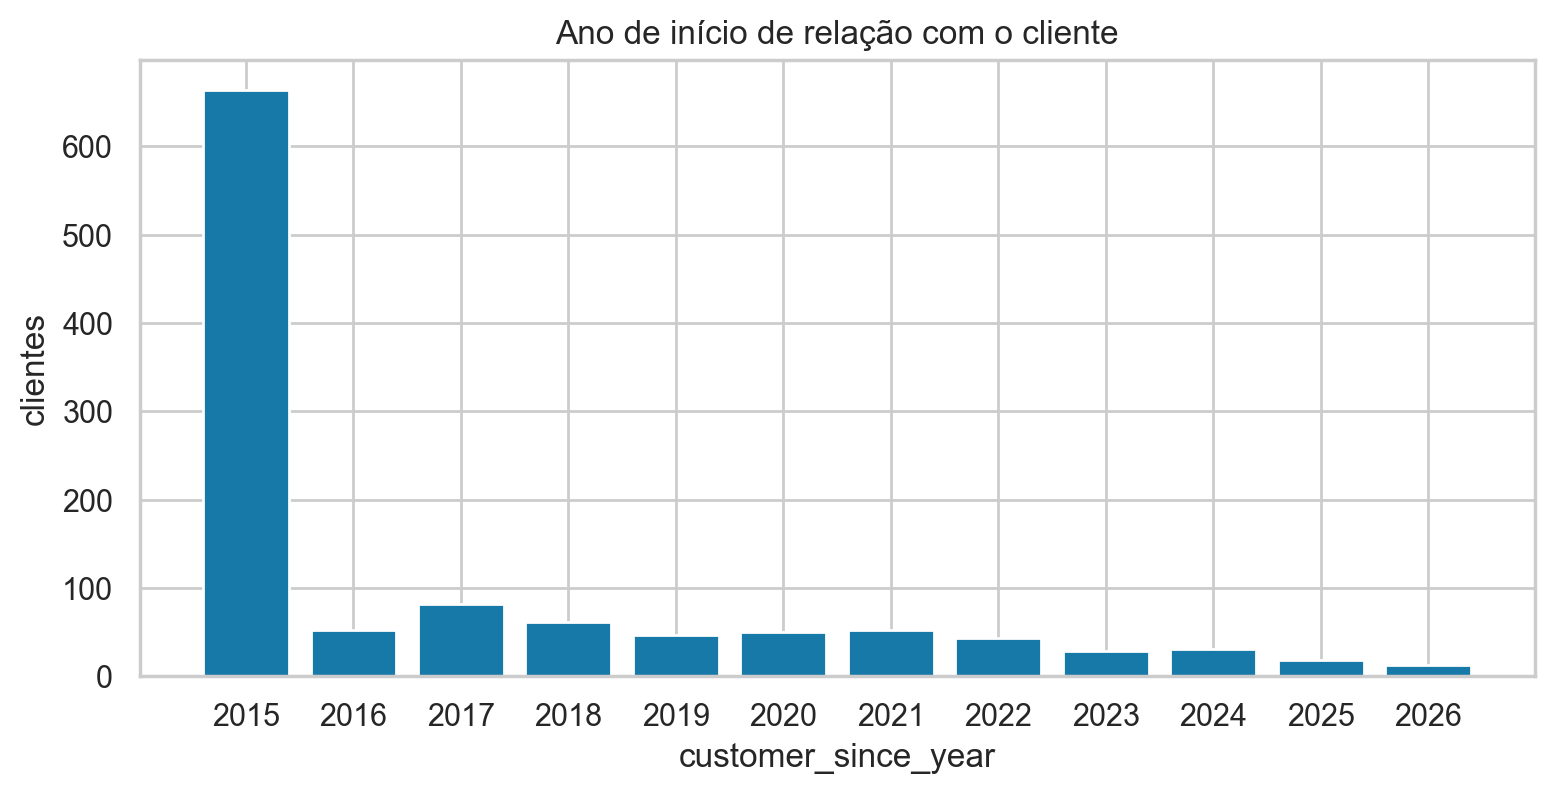

58.1% dos clientes têm customer_since_year = 2015; a primeira compra do treino é de 2015-07-11


In [45]:
since = clientes["customer_since_year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(since.index.astype(str), since.values, color=PLOT_BLUE)
ax.set(xlabel="customer_since_year", ylabel="clientes",
       title="Ano de início de relação com o cliente")
plt.show()
print(f"{100 * since.iloc[0] / since.sum():.1f}% dos clientes têm customer_since_year = {since.index[0]};"
      f" a primeira compra do treino é de {train_dates.min().date()}")

<div class="alert alert-block alert-warning">

**Das 12 colunas de `clientes.csv`, só uma minoria pode ser usada como feature.**

- **`customer_type` está 100% vazia** em todos os 1,143 clientes: não tem nada para dar.
- **`company_name` (1,141 valores) e `address` (1,120) são identificadores:** praticamente um valor por cliente.
- **A hierarquia geográfica degrada-se depressa.** `city`, `postal_code`, `street` e `address` têm mediana de 1 cliente por nível, e centenas de níveis com um único cliente. Um modelo que as receba aprende *quem* é o cliente, não *onde* está. `municipality` e `postal_area` (mediana de 2) estão no limite.
- **As candidatas reais são `country_or_region` (11 níveis), `commercial_region` (37) e `island` (10).** O país está muito concentrado (CT10 tem 94% dos clientes).
- **`island` em falta é quase sempre "não se aplica":** está vazia em 100% dos clientes fora do país CT10 e em 47.6% dos de CT10 (presumivelmente o continente). Deve ser codificada como um nível próprio, não imputada.
- **`customer_since_year` está censurada à esquerda:** 58.1% dos clientes têm 2015, que é também o ano em que começam os dados. "2015" quer dizer "2015 ou antes".

A chave está completa: **todos os clientes do treino e do teste estão em `clientes.csv`**, e os 511 restantes são clientes sem compras nestes ficheiros, que o left join ignora.

</div>

# <font color='#1779A8'>15. Merge por `customer_id`</font> <a class="anchor" id="merge"></a>
[Voltar ao índice](#toc)

__Passo 38:__ Left join de cada ocasião de compra ao seu cliente. `validate=
"many_to_one"` faz o pandas falhar se algum `customer_id` estiver repetido em
`clientes.csv`, o que duplicaria compras em silêncio. O mesmo merge é aplicado ao
teste, só para o descrever; o índice `ID` é preservado.

In [46]:
def merge_clients(frame):
    """Junta clientes.csv a cada linha de `frame`, mantendo o índice ID e a ordem."""
    merged = frame.reset_index().merge(clientes, on="customer_id", how="left",
                                       validate="many_to_one")
    return merged.set_index("ID")


train_merged = merge_clients(train)
test_merged = merge_clients(test)

for name, before, after in [("treino", train, train_merged), ("teste", test, test_merged)]:
    print(f"{name}: {before.shape} -> {after.shape} | mesmas linhas e ordem:"
          f" {after.index.equals(before.index)} | linhas sem cliente correspondente:"
          f" {after['customer_since_year'].isna().sum()}")

treino: (6534, 38) -> (6534, 50) | mesmas linhas e ordem: True | linhas sem cliente correspondente: 0
teste: (986, 37) -> (986, 49) | mesmas linhas e ordem: True | linhas sem cliente correspondente: 0


In [47]:
train_merged[["customer_id", date_column, TARGET] + client_columns].head()

,customer_id,purchase_date,repeat_purchase_90d,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
ID,,,,,,,,,,,,,,,
10000000,660784,2024-10-29,1,Country CT10: Land of The Final Version,Region RG25: We Will See Later,NaN,Municipality MU89: Council of Last Minute Edits,City CY286: Cached Result Falls,Postal area PA228: Hidden Sheet Sector,Postal code PC444: #REF! Delivery Route,Street ST303: Absolute Reference Terrace,Address AD761: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1013,2024
10000001,189146,2017-07-08,1,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,Municipality MU11: Council of Last Minute Edits,City CY147: VLOOKUP Bay,Postal area PA260: Hidden Sheet Sector,Postal code PC636: #REF! Delivery Route,NaN,Address AD382: Cell Without a Home,NaN,Excel Is Not A Database Ltd 35,2015
10000002,103940,2019-03-19,1,Country CT10: Land of The Final Version,Region RG23: We Will See Later,NaN,Municipality MU70: Council of Last Minute Edits,City CY265: Where-less Query Falls,Postal area PA84: Hidden Sheet Sector,Postal code PC200: #REF! Delivery Route,NaN,Address AD723: Cell Without a Home,NaN,Excel Is Not A Database Ltd 826,2017
10000003,512927,2018-11-10,0,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA253: Hidden Sheet Sector,Postal code PC558: #REF! Delivery Route,Street ST144: Last Save Court,Address AD399: Cell Without a Home,NaN,Excel Is Not A Database Ltd 530,2018
10000004,122356,2021-11-30,1,Country CT10: Land of The Final Version,Region RG31: We Will See Later,NaN,Municipality MU142: Council of Last Minute Edits,City CY359: Spill Error Ridge,Postal area PA136: Hidden Sheet Sector,Postal code PC300: #REF! Delivery Route,Street ST395: AutoFill Path,Address AD928: Cell Without a Home,NaN,Excel Is Not A Database Ltd 220,2017


# <font color='#1779A8'>16. Qualidade das novas colunas</font> <a class="anchor" id="merged_quality"></a>
[Voltar ao índice](#toc)

Depois do merge, cada atributo de cliente é repetido em todas as compras desse
cliente. Duas consequências: a % de faltas por **linha** pode ser muito diferente
da % por **cliente**, e o tamanho efetivo da amostra destas colunas é o número de
clientes (610), não o número de linhas.

__Passo 39:__ Faltas por cliente e por linha, no treino e no teste.

In [48]:
customers_train = clientes[clientes["customer_id"].isin(train["customer_id"])]
merged_missing = pd.DataFrame({
    "% faltas (clientes do treino)": 100 * customers_train[client_columns].isna().mean(),
    "% faltas (linhas do treino)": 100 * train_merged[client_columns].isna().mean(),
    "% faltas (linhas do teste)": 100 * test_merged[client_columns].isna().mean(),
}).round(1)
merged_missing.sort_values("% faltas (linhas do treino)", ascending=False)

,% faltas (clientes do treino),% faltas (linhas do treino),% faltas (linhas do teste)
customer_type,100.0,100.0,100.0
street,54.1,58.7,62.5
island,46.9,33.8,41.8
city,38.7,32.9,35.7
postal_area,6.6,4.3,9.5
postal_code,3.3,3.4,2.0
municipality,6.7,3.3,8.9
commercial_region,2.0,0.5,0.9
country_or_region,0.0,0.0,0.0
address,0.0,0.0,0.0


__Passo 40:__ Consistência temporal: o cliente não pode ter começado depois da
compra, e `customer_since_year` deve concordar com `customer_tenure_days`.

In [49]:
m = train_merged[~empty_rows]
purchase_year = pd.to_datetime(m[date_column]).dt.year
first_year_from_tenure = (pd.to_datetime(m[date_column])
                          - pd.to_timedelta(m["customer_tenure_days"], unit="D")).dt.year
print("customer_since_year > ano da compra:", int((m["customer_since_year"] > purchase_year).sum()))
print("customer_since_year > ano da 1.ª compra implícito na tenure:",
      int((m["customer_since_year"] > first_year_from_tenure).sum()))
print("r(customer_since_year, customer_tenure_days):",
      round(m["customer_since_year"].corr(m["customer_tenure_days"]), 3))
print("r(anos de relação = ano da compra - since, tenure):",
      round((purchase_year - m["customer_since_year"]).corr(m["customer_tenure_days"]), 3))

diff = first_year_from_tenure - m["customer_since_year"]
print("\nano da 1.ª compra (pela tenure) - customer_since_year:")
print(diff.describe().round(2).to_frame().T.to_string())

customer_since_year > ano da compra: 0
customer_since_year > ano da 1.ª compra implícito na tenure: 0
r(customer_since_year, customer_tenure_days): -0.316
r(anos de relação = ano da compra - since, tenure): 0.917

ano da 1.ª compra (pela tenure) - customer_since_year:
    count  mean   std  min  25%  50%  75%  max
0  6469.0  0.53  1.06  0.0  0.0  0.0  1.0  9.0


<div class="alert alert-block alert-success">

**O merge é seguro e não introduz incoerências.** As linhas e a ordem mantêm-se nos dois ficheiros, não há compras sem cliente correspondente, e o ano de início do cliente nunca é posterior à compra nem à primeira compra implícita em `customer_tenure_days`.

**Mas `customer_since_year` é quase redundante.** Convertida em anos de relação (ano da compra menos `customer_since_year`), tem uma correlação de **0.92** com `customer_tenure_days`. A diferença entre as duas é, na mediana, 0 anos. O pouco que acrescenta vem da censura de 2015.

**As faltas por linha diferem das faltas por cliente:** `island` falta a 46.9% dos clientes mas só a 33.8% das linhas, porque os clientes com ilha preenchida compram mais vezes. Qualquer estatística destas colunas pesa os clientes pelo número de compras.

</div>

# <font color='#1779A8'>17. Novas colunas e o target</font> <a class="anchor" id="merged_relevance"></a>
[Voltar ao índice](#toc)

__Passo 41:__ A mesma tabela de associação da secção 10, agora para as colunas de
cliente. Ao lado do V de Cramér fica o número de **clientes por nível**: com
centenas de níveis de um ou dois clientes, um V alto mede que a coluna identifica o
cliente, não que a geografia explique a recompra.

In [50]:
mv = train_merged[~empty_rows]
client_categorical = [c for c in client_columns
                      if c != "customer_since_year" and mv[c].notna().any()]
merged_relevance = []
for column in client_categorical:
    statistic, p, v_cramer, min_expected = cramers_v(mv[column].fillna("(falta)"), mv[TARGET])
    per_level = customers_train[column].fillna("(falta)").value_counts()
    merged_relevance.append({
        "coluna": column, "níveis": mv[column].nunique(), "V de Cramér": v_cramer, "p": p,
        "menor esperado": min_expected,
        "mediana de clientes por nível": per_level.median(),
    })
r, p = pointbiserialr(mv[TARGET], mv["customer_since_year"])
merged_relevance.append({"coluna": "customer_since_year (|r| point-biserial)",
                         "níveis": mv["customer_since_year"].nunique(), "V de Cramér": abs(r),
                         "p": p, "mediana de clientes por nível":
                         customers_train["customer_since_year"].value_counts().median()})
pd.DataFrame(merged_relevance).set_index("coluna").sort_values(
    "V de Cramér", ascending=False).round(4)

,níveis,V de Cramér,p,menor esperado,mediana de clientes por nível
coluna,,,,,
company_name,606,0.5919,0.0000,0.4403,1.0
address,597,0.5904,0.0000,0.4403,1.0
postal_code,516,0.5652,0.0000,0.4403,1.0
city,259,0.4317,0.0000,0.4403,1.0
postal_area,188,0.3888,0.0000,0.4403,1.0
street,264,0.3720,0.0000,0.4403,1.0
municipality,150,0.3650,0.0000,0.4403,2.0
commercial_region,32,0.2639,0.0000,0.4403,9.0
island,10,0.1476,0.0000,4.4025,27.0


__Passo 42:__ As três colunas de cliente com níveis largos o suficiente para serem
lidas como categorias: taxa de recompra por nível, só para níveis com pelo menos 5
clientes.

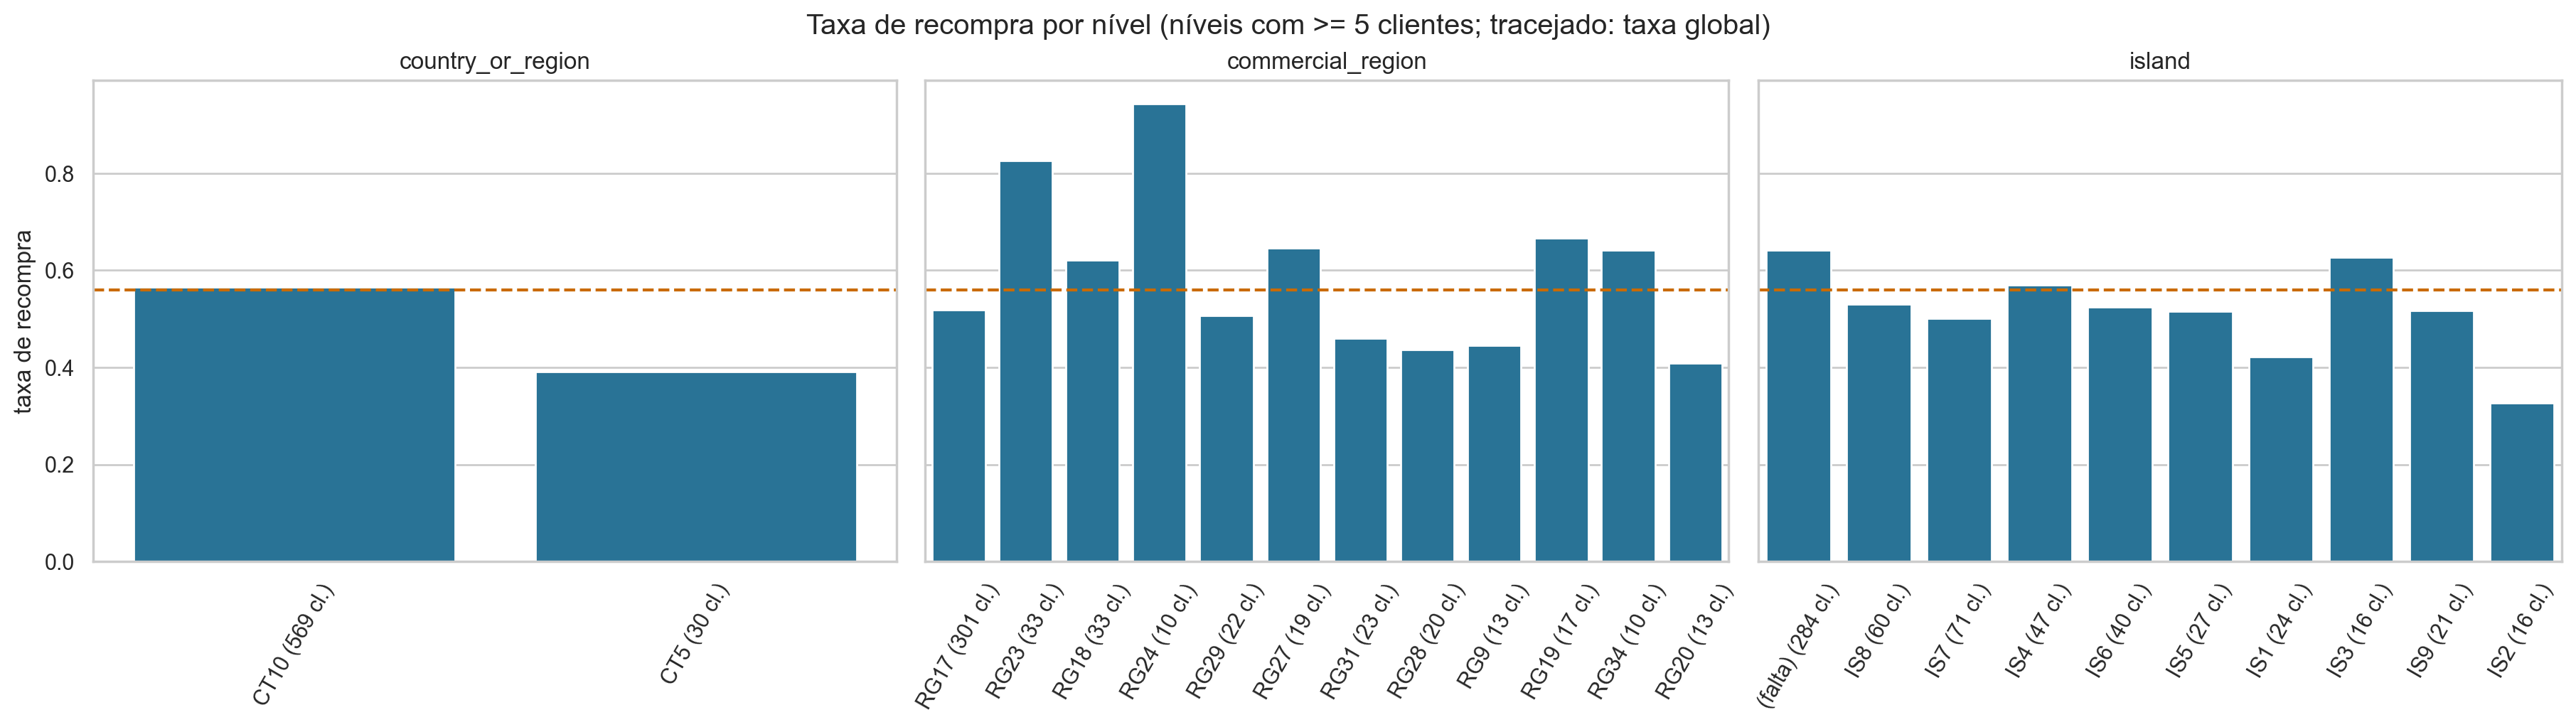

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True, layout="constrained")
for column, ax in zip(["country_or_region", "commercial_region", "island"], axes):
    values = mv[column].fillna("(falta)")
    customers_per_level = mv.groupby(values)["customer_id"].nunique()
    keep = customers_per_level[customers_per_level >= 5].index
    rates = (mv[values.isin(keep)].groupby(values[values.isin(keep)])[TARGET]
             .agg(["size", "mean"]).sort_values("size", ascending=False).head(12))
    # Rótulo curto: só o código do nível (CT10, RG17, IS7...).
    names = pd.Series(rates.index)
    codes = names.str.extract(r"([A-Z]{2}\d+)", expand=False).fillna(names)
    labels = [f"{code} ({c} cl.)" for code, c in zip(codes, customers_per_level[rates.index])]
    sns.barplot(x=labels, y=rates["mean"].to_numpy(), color=PLOT_BLUE, ax=ax)
    ax.axhline(mv[TARGET].mean(), color=PLOT_ORANGE, ls="--")
    ax.set(title=column, xlabel="", ylabel="taxa de recompra" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Taxa de recompra por nível (níveis com >= 5 clientes; tracejado: taxa global)")
plt.show()

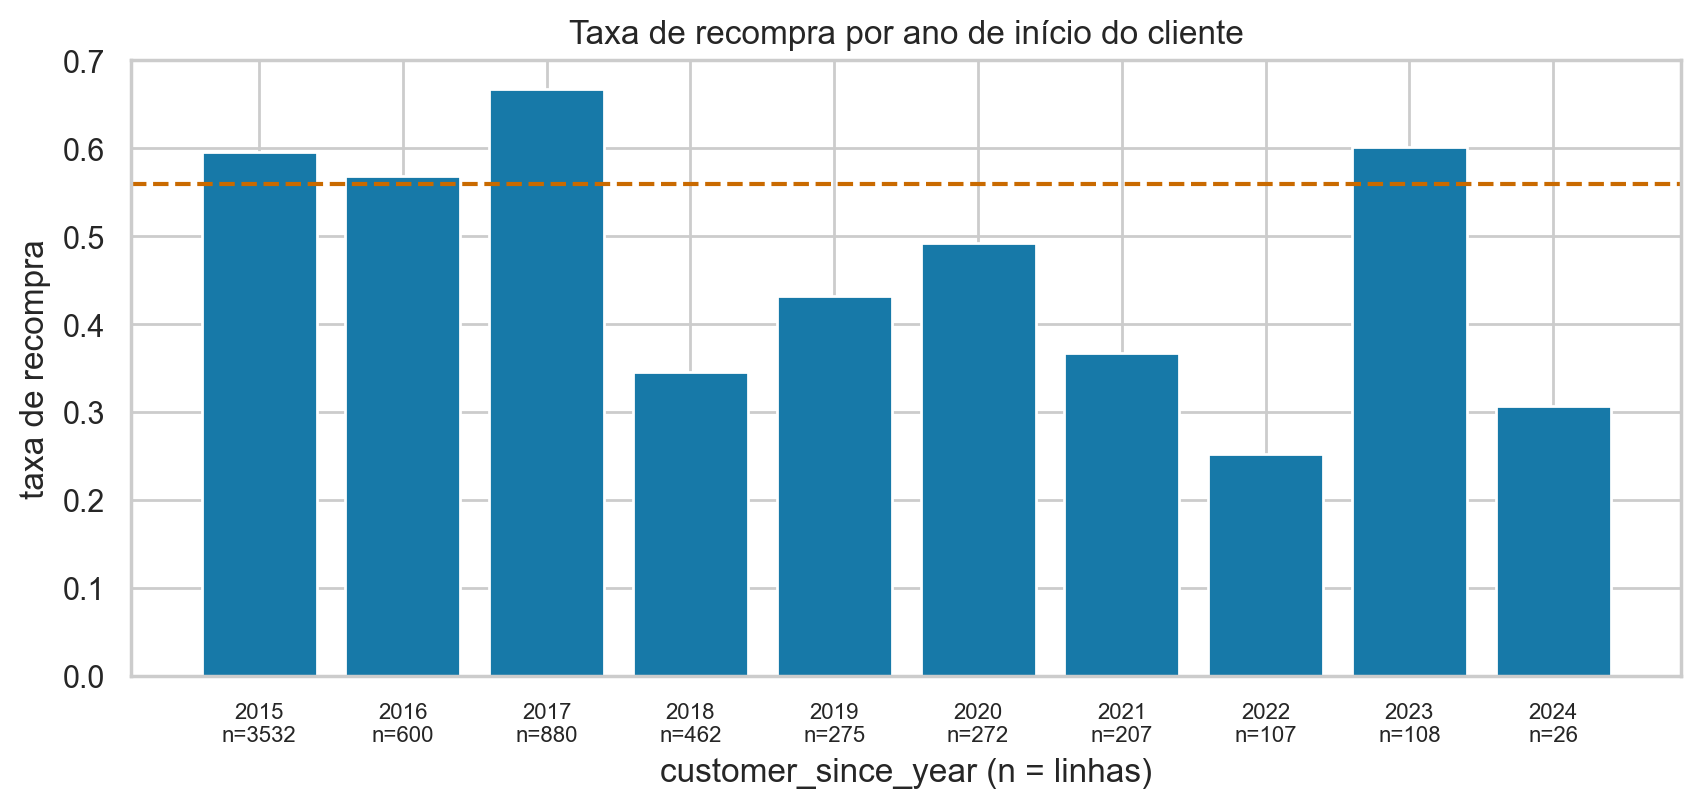

correlação de customer_since_year com o histórico do cliente (r, log1p):
customer_tenure_days   -0.258
prior_purchase_count   -0.291
purchase_count_365d    -0.192


In [52]:
fig, ax = plt.subplots(figsize=(10, 4))
rates = mv.groupby("customer_since_year")[TARGET].agg(["size", "mean"])
ax.bar([f"{year}\nn={n}" for year, n in zip(rates.index, rates["size"])], rates["mean"],
       color=PLOT_BLUE)
ax.tick_params(axis="x", labelsize=8)
ax.axhline(mv[TARGET].mean(), color=PLOT_ORANGE, ls="--")
ax.set(xlabel="customer_since_year (n = linhas)", ylabel="taxa de recompra",
       title="Taxa de recompra por ano de início do cliente")
plt.show()

print("correlação de customer_since_year com o histórico do cliente (r, log1p):")
print(np.log1p(mv[["customer_tenure_days", "prior_purchase_count", "purchase_count_365d"]])
      .corrwith(mv["customer_since_year"]).round(3).to_string())

<div class="alert alert-block alert-warning">

**Os V de Cramér mais altos são os das colunas que identificam o cliente, e por isso não significam nada.** `company_name` (0.59), `address` (0.59), `postal_code` (0.57) e `city` (0.43) têm mediana de 1 cliente por nível. Um V alto aqui diz apenas que a taxa de recompra varia entre clientes, o que já se sabia. Estas colunas seriam um caminho direto para o overfitting, sobretudo porque 184 dos 206 clientes do teste estão no treino.

**Com níveis largos o suficiente, há algum sinal:**

- **`commercial_region` (V 0.26, mediana de 9 clientes por nível):** algumas regiões têm taxas muito acima da média (RG24 0.95 e RG23 0.82, contra 0.56 no total), mas parte deste efeito vem de poucos clientes muito ativos em cada região.
- **`island` (V 0.15):** não ter ilha (continente, ou fora de CT10) está associado a mais recompra (0.64).
- **`customer_since_year` (|r| 0.12):** clientes mais recentes recompram menos (0.25 nos que começaram em 2022 contra 0.60 nos de 2015). O mesmo sinal já está em `customer_tenure_days` e `prior_purchase_count`, com os quais tem correlação negativa (r entre -0.19 e -0.29 em log1p).
- **`country_or_region` (V 0.07):** o país CT5 (194 linhas) recompra menos (0.39), mas quase todos os clientes são de CT10.

</div>

# <font color='#1779A8'>18. Resumo final e decisões para o pré-processamento</font> <a class="anchor" id="summary_b"></a>
[Voltar ao índice](#toc)

<div class="alert alert-block alert-info">

**Vale a pena fazer o merge?** Sim, mas só de três colunas. `clientes.csv` cobre todos os clientes, o merge não altera nenhuma linha, e acrescenta informação geográfica que o `train.csv` não tem. O resto da tabela é vazio, identificador ou redundante.

| coluna de `clientes.csv` | decisão | porquê |
|---|---|---|
| `commercial_region` | **manter**, agrupando regiões raras | sinal mais forte entre as colunas de cliente, níveis com clientes suficientes |
| `island` | **manter**, com falta = nível próprio | a falta significa "sem ilha" e está associada ao target |
| `country_or_region` | **manter** ou agrupar em CT10 / CT5 / outros | sinal fraco, mas legítimo |
| `customer_since_year` | candidata, a comparar na seleção | quase redundante com `customer_tenure_days` (r 0.92 em anos de relação) |
| `municipality`, `postal_area` | remover | 1-2 clientes por nível: identificam o cliente |
| `city`, `postal_code`, `street`, `address`, `company_name` | remover | identificadores, ~1 cliente por nível |
| `customer_type` | remover | 100% em falta |

**Para o pré-processamento** ficam as decisões da tabela da secção 13, mais estas: as transformações (imputação, agrupamento de níveis, codificação, escalonamento) são ajustadas **só no treino** e aplicadas ao teste pela mesma função. A validação deve respeitar a ordem temporal, e o teste deve passar pelo mesmo merge (`merge_clients`) antes de qualquer transformação.

</div>